In [63]:
import numpy as np
import time
import pandas as pd
import matplotlib.pyplot as plt
import mealpy
import seaborn as sns
from mealpy import GWO, PSO, WOA, HHO, GA
from greyhaven_problem import GreyhavenProblem
import pkgutil, inspect, importlib
from mealpy.optimizer import Optimizer
import logging
logging.disable(logging.INFO)
logging.disable(logging.WARNING)

In [80]:
import greyhaven_problem
import importlib

importlib.reload(greyhaven_problem)

from greyhaven_problem import GreyhavenProblem

In [65]:
def run_experiment(situation, model, assignment, n_runs=31, max_fe=10000):

    results = []
    convergence = []
    runtimes = []
    solutions = []

    for run in range(n_runs):

        problem = GreyhavenProblem(situation=situation,assignment=assignment)
        start = time.time()
        best = model.solve(
            problem,
            termination={"max_fe": max_fe},
            seed=run + 1
        )
        solutions.append(best.solution)
        runtime = time.time() - start
        runtimes.append(runtime)
        results.append(best.target.fitness)
        convergence.append(model.history.list_global_best_fit)

        print(
            f"\nRun {run + 1}/{n_runs} | "
            f"Fitness: {best.target.fitness:.6f} | "
            f"Epochs: {len(model.history.list_global_best_fit)} | "
            f"Time: {runtime:.2f}s"
        )

    return np.array(results), convergence, np.array(runtimes), solutions

In [67]:
def plot_all_results(all_results, algorithms=None):

    # Select algorithms
    if algorithms is None:
        algorithms = list(all_results.keys())

    names = algorithms

    fitness_data = [all_results[name][0] for name in names]
    convergence_data = [all_results[name][1] for name in names]
    runtime_data = [all_results[name][2] for name in names]

    sns.set_theme(style="whitegrid", context="talk")

    # 1. Box plot
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=fitness_data, showfliers=False)
    sns.stripplot(
        data=fitness_data,
        color="black",
        alpha=0.4,
        size=4,
        jitter=True
    )

    plt.xticks(range(len(names)), names)
    plt.title("Fitness Distribution")
    plt.xlabel("Algorithm")
    plt.ylabel("Best Fitness")
    plt.tight_layout()
    plt.show()

    # 2. Convergence curves
    fig, (ax1, ax2) = plt.subplots(
        1, 2, figsize=(16, 6)
    )

    for name, curves in zip(names, convergence_data):

        curves = [np.asarray(c).flatten() for c in curves]

        if not curves or min(map(len, curves)) == 0:
            continue

        min_length = min(map(len, curves))
        curves = np.array([c[:min_length] for c in curves])

        mean_curve = np.mean(curves, axis=0)
        std_curve = np.std(curves, axis=0)

        iterations = np.arange(1, min_length + 1)

        # Full convergence
        ax1.plot(iterations, mean_curve, label=name, linewidth=2)
        ax1.fill_between(
            iterations,
            mean_curve - std_curve,
            mean_curve + std_curve,
            alpha=0.12
        )

        # Zoomed convergence
        zoom_length = max(2, int(min_length * 0.10))

        ax2.plot(
            iterations[:zoom_length],
            mean_curve[:zoom_length],
            label=name,
            linewidth=2
        )

        ax2.fill_between(
            iterations[:zoom_length],
            (mean_curve - std_curve)[:zoom_length],
            (mean_curve + std_curve)[:zoom_length],
            alpha=0.12
        )

    ax1.set_title("Full Convergence")
    ax1.set_xlabel("Iteration")
    ax1.set_ylabel("Best Fitness")
    ax1.legend()

    ax2.set_title("Early Convergence (First 10%)")
    ax2.set_xlabel("Iteration")
    ax2.set_ylabel("Best Fitness")
    ax2.legend()

    ax1.grid(alpha=0.3)
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    # 3. Runtime comparison
    means = [np.mean(r) for r in runtime_data]
    stds = [np.std(r, ddof=1) for r in runtime_data]
    
    plt.figure(figsize=(10, 6))
    bars = plt.bar(names, means, yerr=stds, capsize=5)

    for bar, value in zip(bars, means):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.2f}s",
            ha="center",
            va="bottom",
            fontsize=9
        )

    plt.title("Execution Time")
    plt.xlabel("Algorithm")
    plt.ylabel("Runtime (seconds)")
    plt.tight_layout()
    plt.show()

    # 4. Best fitness comparison
    best_values = [np.min(f) for f in fitness_data]

    plt.figure(figsize=(10, 6))

    bars = plt.bar(names, best_values)

    for bar, value in zip(bars, best_values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.5f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

    plt.title("Best Fitness Achieved")
    plt.xlabel("Algorithm")
    plt.ylabel("Best Fitness")
    plt.tight_layout()
    plt.show()


In [68]:
def plot_individual_convergence(all_results, algorithms=None, zoom=0.10):

    if algorithms is None:
        algorithms = list(all_results.keys())

    for name in algorithms:

        if name not in all_results:
            raise ValueError(f"Unknown algorithm: {name}")

        curves = all_results[name][1]

        curves = [
            np.asarray(c).flatten()
            for c in curves
            if len(c) > 0
        ]

        if not curves:
            continue

        min_length = min(map(len, curves))
        curves = np.array([c[:min_length] for c in curves])

        iterations = np.arange(1, min_length + 1)
        mean_curve = np.mean(curves, axis=0)
        std_curve = np.std(curves, axis=0)
        zoom_length = max(2, int(min_length * zoom))

        fig, (ax1, ax2) = plt.subplots(
            1, 2, figsize=(17, 6)
        )

        # Full convergence
        for seed, curve in enumerate(curves, start=1):
            ax1.plot(
                iterations,
                curve,
                linewidth=1.2,
                alpha=0.45,
                label=f"Seed {seed}"
            )

        ax1.plot(
            iterations,
            mean_curve,
            color="black",
            linewidth=3,
            label="Mean"
        )

        # Zoomed convergence
        for curve in curves:
            ax2.plot(
                iterations[:zoom_length],
                curve[:zoom_length],
                linewidth=1.2,
                alpha=0.45
            )

        ax2.plot(
            iterations[:zoom_length],
            mean_curve[:zoom_length],
            color="black",
            linewidth=3,
            label="Mean"
        )

        ax2.fill_between(
            iterations[:zoom_length],
            mean_curve[:zoom_length] - std_curve[:zoom_length],
            mean_curve[:zoom_length] + std_curve[:zoom_length],
            alpha=0.15,
            label="±1 STD"
        )

        ax1.set_title(f"{name} - Full Convergence")
        ax2.set_title(f"{name} - First {zoom * 100:.0f}%")

        for ax in (ax1, ax2):
            ax.set_xlabel("Iteration")
            ax.set_ylabel("Best Fitness")
            ax.grid(alpha=0.3)

        ax1.legend(fontsize=8, ncol=2)
        ax2.legend()

        plt.tight_layout()
        plt.show()

In [69]:
def create_summary_table(all_results):

    rows = []

    for name, (results, convergence, runtimes, solutions) in all_results.items():

        rows.append({
            "Algorithm": name,
            "Mean Fitness": np.mean(results),
            "Std Fitness": np.std(results, ddof=1),
            "Best Fitness": np.min(results),
            "Worst Fitness": np.max(results),
            "Mean Runtime (s)": np.mean(runtimes),
            "Std Runtime (s)": np.std(runtimes, ddof=1)
        })

    return pd.DataFrame(rows).sort_values(
        "Best Fitness"
    ).reset_index(drop=True)

In [70]:
def create_best_solutions_table(all_results, situation="Initial response", assignment="A"):

    rows = []

    for name, data in all_results.items():

        results, _, _, solutions = data
        best_run = np.argmin(results)
        solution = solutions[best_run]

        problem = GreyhavenProblem(
            situation=situation,
            assignment=assignment
        )
        decoded = problem.decode_solution(solution)

        row = {
            "Algorithm": name,
            "Best Fitness": results[best_run]
        }

        for i in range(4):
            for v in ["x", "y", "p", "h", "c", "z"]:
                row[f"{v}{i+1}"] = decoded[f"{v}{i}"]

        rows.append(row)

    return pd.DataFrame(rows).sort_values("Best Fitness")

In [71]:
def plot_best_deployments(all_results, situation="Initial response", assignment="A"):

    for name, (results, _, _, solutions) in all_results.items():

        best_run = np.argmin(results)
        best_solution = solutions[best_run]

        print(f"\n{name} | Best fitness: {results[best_run]:.6f}")

        problem = GreyhavenProblem(
            situation=situation,
            assignment=assignment
        )

        decoded = problem.decode_solution(best_solution)

        stations = np.array([
            [decoded[f"{v}{i}"] for v in ["x", "y", "p", "h", "c", "z"]]
            for i in range(4)
        ], dtype=float)

        problem.plot_deployment(stations)

In [72]:
algorithms = {
    "GA": GA.BaseGA,
    "IGWO": GWO.IGWO,
    "PSO": PSO.OriginalPSO,
    "GWO": GWO.OriginalGWO,
    "WOA": WOA.OriginalWOA,
    "HHO": HHO.OriginalHHO
}

# Assignment A

## Initial response

In [82]:
all_results = {}
selected_algorithms = {
    name: algorithms[name]
    for name in ["IGWO", "PSO", "GWO"]
}
for name, optimizer in selected_algorithms.items():

    print(f"\n========== {name} ==========")
    model = optimizer(epoch=10000, pop_size=50)
    all_results[name] = run_experiment(
        "Initial response",
        model,
        assignment="A"
    )


========== IGWO ==========

Run 1/31 | Fitness: -0.873883 | Epochs: 199 | Time: 5.15s

Run 2/31 | Fitness: -0.882972 | Epochs: 199 | Time: 4.75s

Run 3/31 | Fitness: -0.875074 | Epochs: 199 | Time: 5.31s

Run 4/31 | Fitness: -0.859471 | Epochs: 199 | Time: 5.02s

Run 5/31 | Fitness: -0.852806 | Epochs: 199 | Time: 6.19s

Run 6/31 | Fitness: -0.875175 | Epochs: 199 | Time: 4.95s

Run 7/31 | Fitness: -0.871618 | Epochs: 199 | Time: 4.84s

Run 8/31 | Fitness: -0.875503 | Epochs: 199 | Time: 4.75s

Run 9/31 | Fitness: -0.854224 | Epochs: 199 | Time: 5.27s

Run 10/31 | Fitness: -0.867615 | Epochs: 199 | Time: 4.90s

Run 11/31 | Fitness: -0.874890 | Epochs: 199 | Time: 4.96s

Run 12/31 | Fitness: -0.871355 | Epochs: 199 | Time: 4.95s

Run 13/31 | Fitness: -0.857506 | Epochs: 199 | Time: 4.98s

Run 14/31 | Fitness: -0.873651 | Epochs: 199 | Time: 5.19s

Run 15/31 | Fitness: -0.853929 | Epochs: 199 | Time: 5.23s

Run 16/31 | Fitness: -0.853973 | Epochs: 199 | Time: 5.59s

Run 17/31 | Fitness:

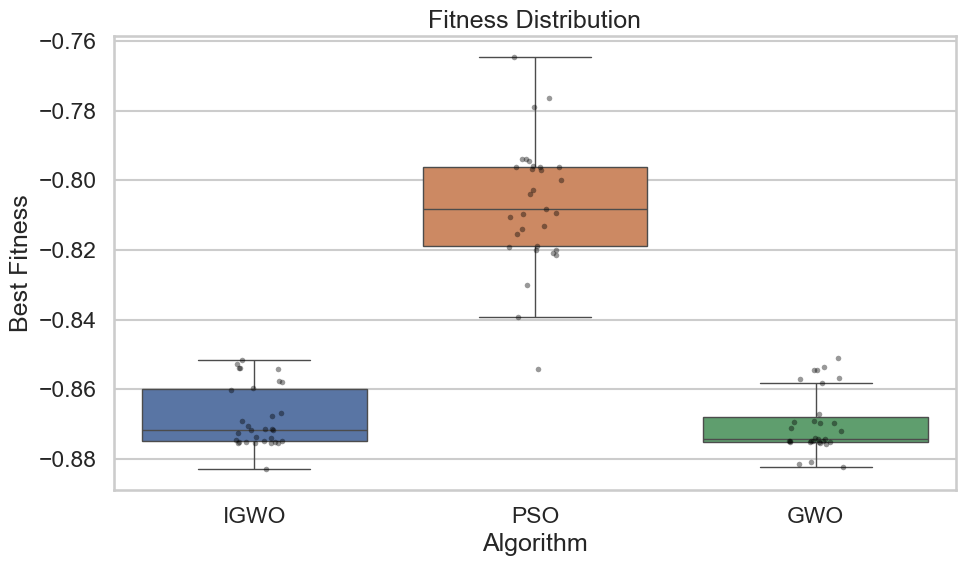

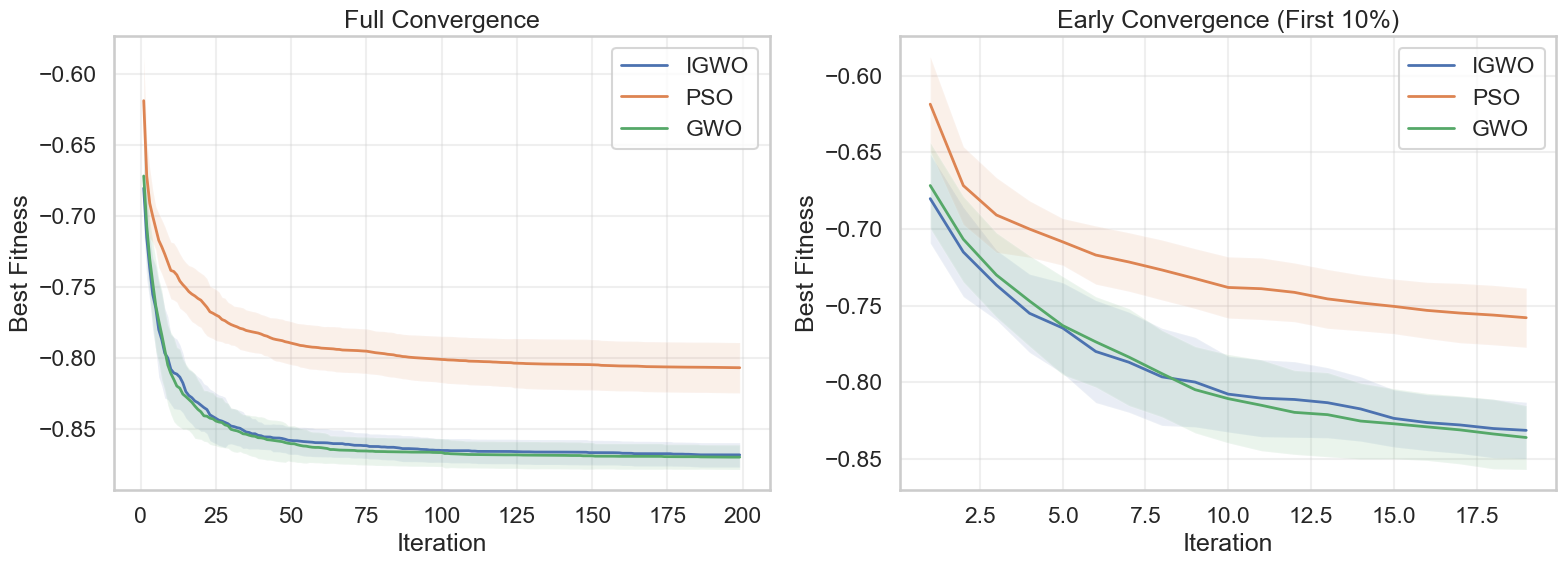

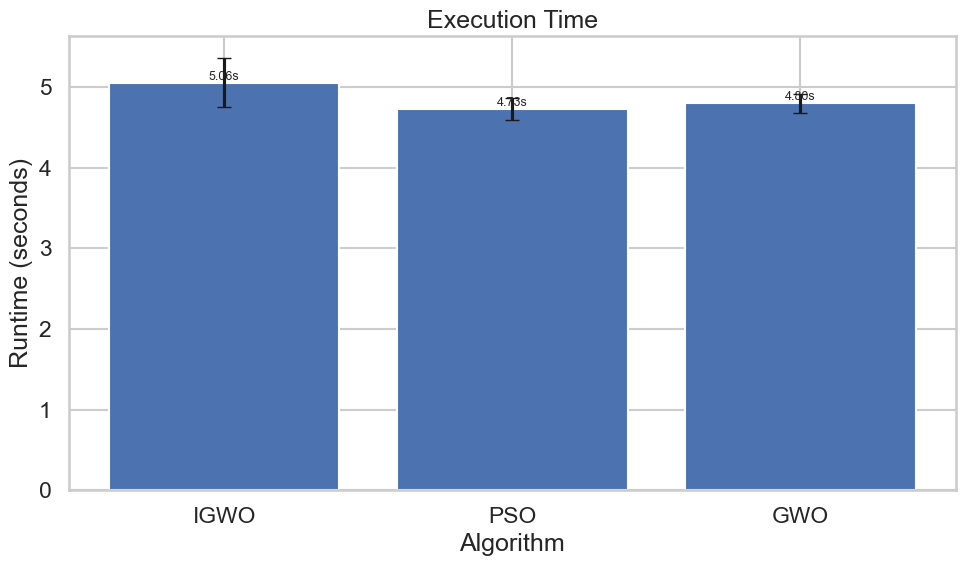

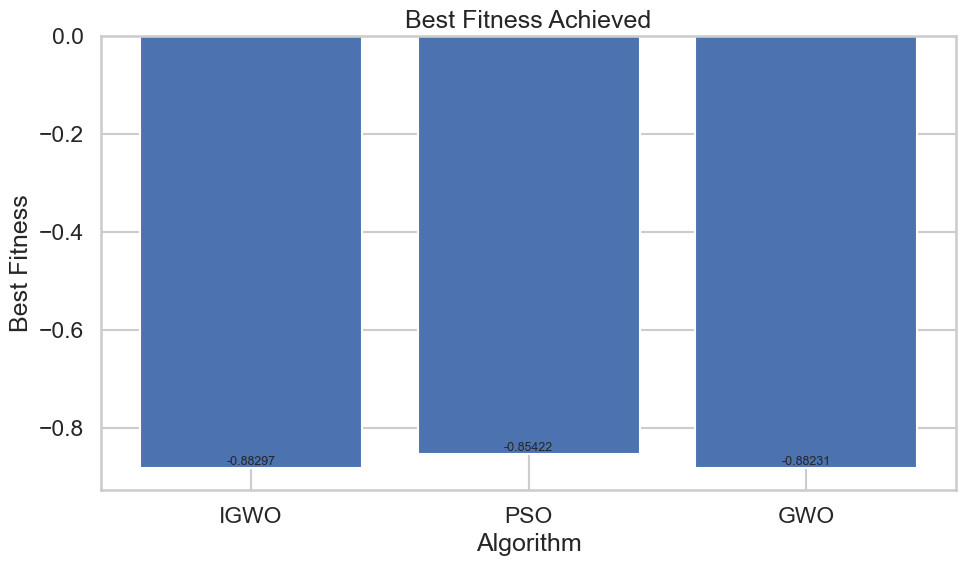

In [83]:
plot_all_results(
    all_results,
    # algorithms=["IGWO", "GWO", "PSO"]
)

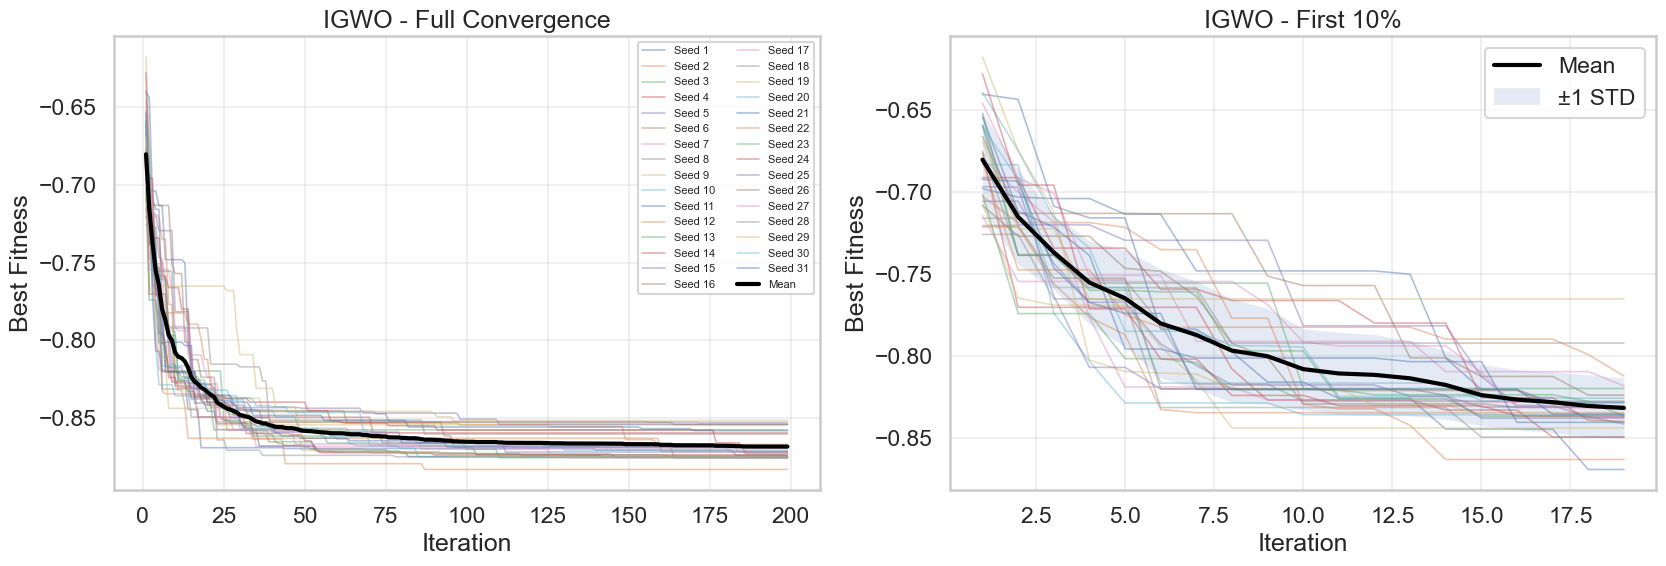

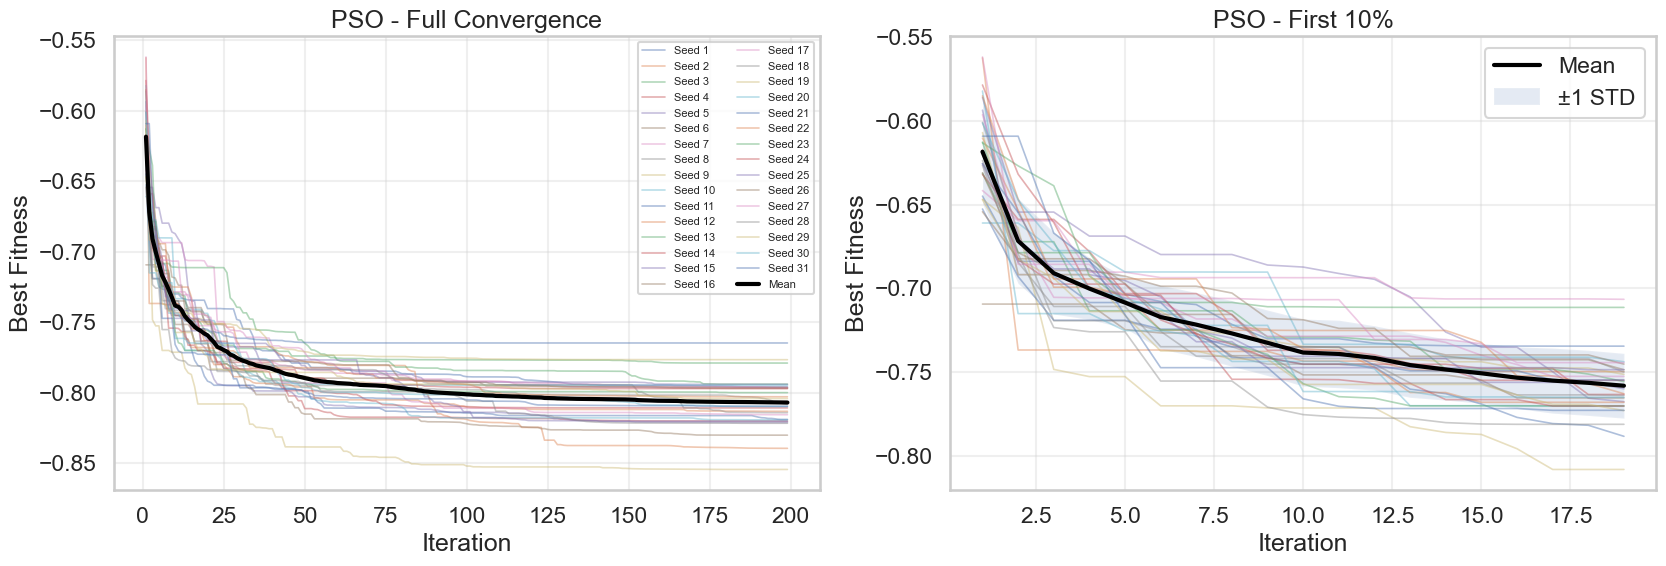

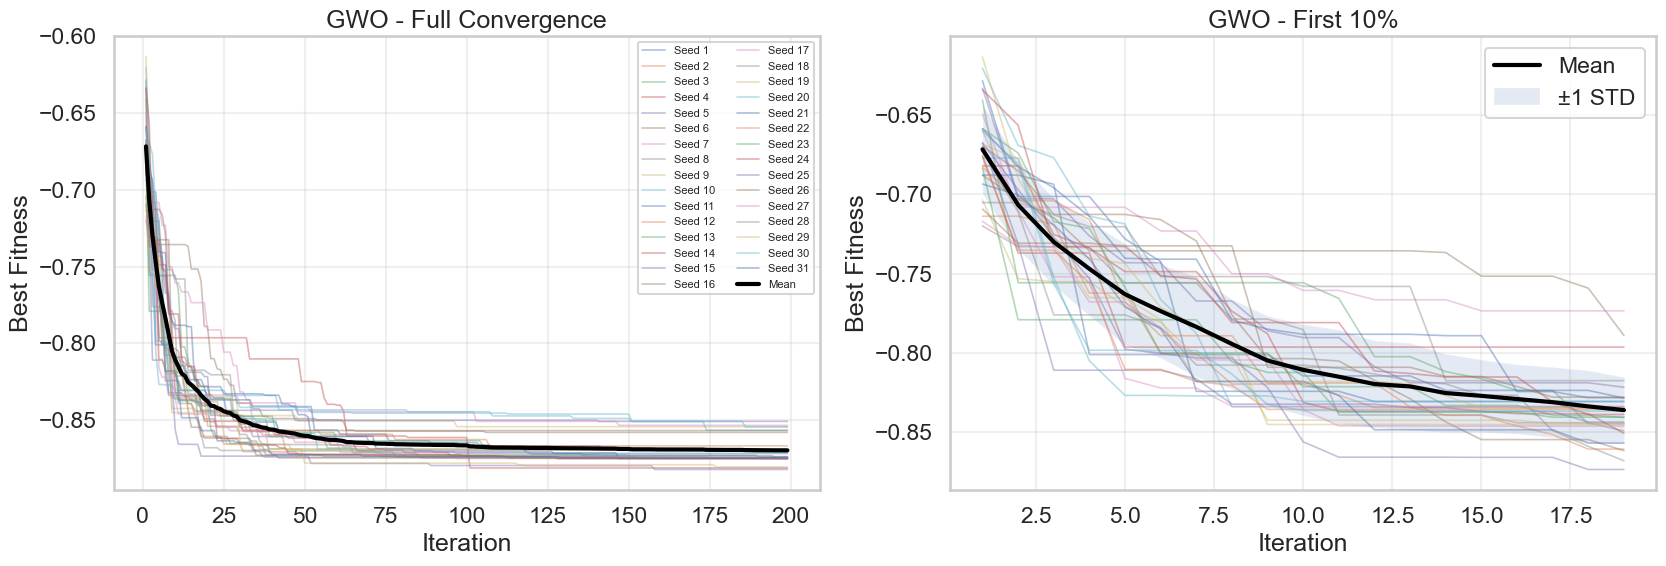

In [84]:
plot_individual_convergence(
    all_results,
    # algorithms=["IGWO", "GWO", "PSO"],
    zoom=0.10
)

In [85]:
summary = create_summary_table(all_results)

display(summary.round(5))

summary.to_csv(
    f"results/A_Initial_response_algorithm_comparison.csv",
    index=False
)

,Algorithm,Mean Fitness,Std Fitness,Best Fitness,Worst Fitness,Mean Runtime (s),Std Runtime (s)
0,IGWO,-0.86826,0.00877,-0.88297,-0.85158,5.05814,0.30707
1,GWO,-0.86985,0.00884,-0.88231,-0.85095,4.80081,0.12287
2,PSO,-0.80680,0.01806,-0.85422,-0.76464,4.73265,0.13932


In [86]:
best_table = create_best_solutions_table(all_results)
display(best_table.round(3))
best_table.to_csv(f"results/A_Initial_response_best_solutions.csv", index=False)

,Algorithm,Best Fitness,x1,y1,p1,h1,c1,z1,x2,y2,...,p3,h3,c3,z3,x4,y4,p4,h4,c4,z4
0,IGWO,-0.883,0.000,10.000,0.200,4,1,1,0.000,10.000,...,0.2,4,1,1,4.605,5.331,2.000,4,1,1
2,GWO,-0.882,0.000,10.000,0.200,4,1,1,0.001,10.000,...,0.2,4,1,1,3.887,5.400,2.000,4,1,1
1,PSO,-0.854,9.143,0.569,0.425,4,1,1,9.953,2.528,...,2.0,4,1,1,9.996,2.255,0.206,4,1,1



IGWO | Best fitness: -0.882972


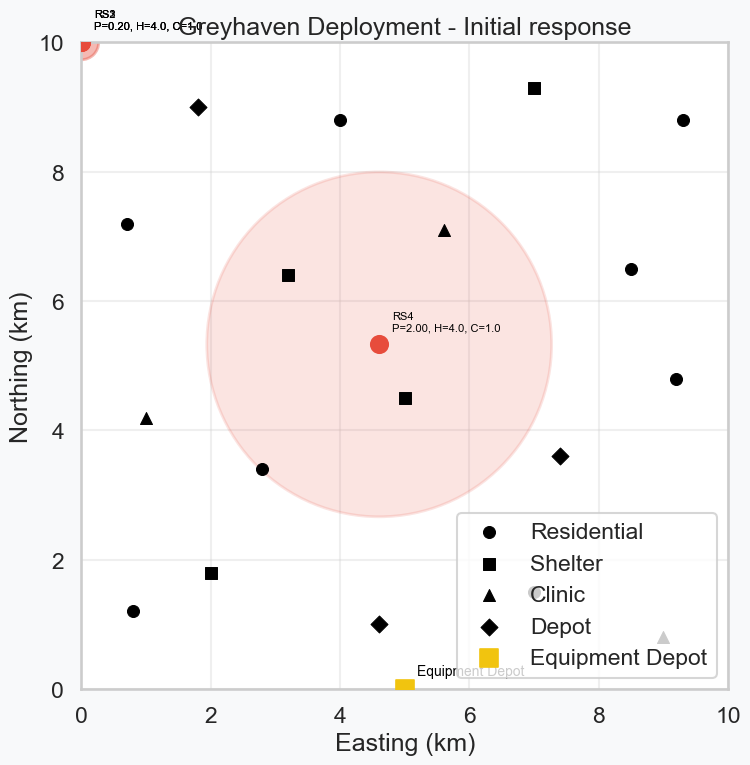


PSO | Best fitness: -0.854221


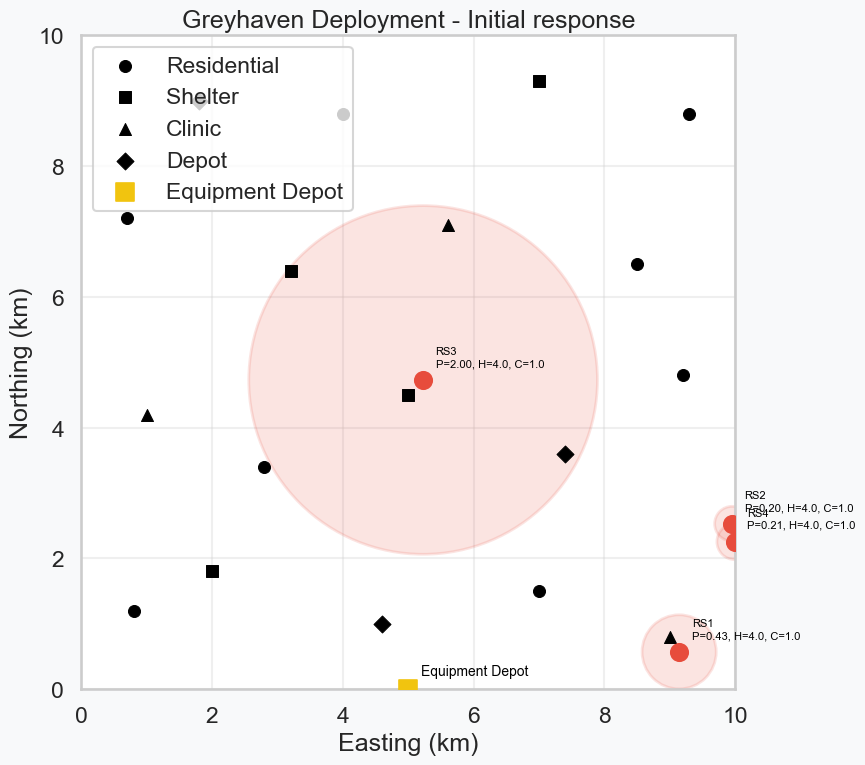


GWO | Best fitness: -0.882308


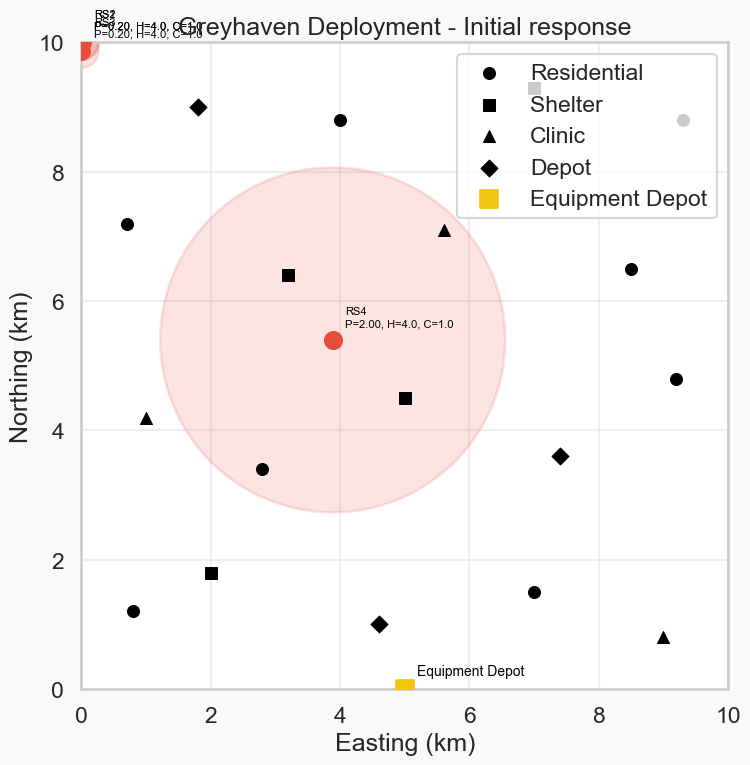

In [87]:
plot_best_deployments(
    all_results,
    situation="Initial response",
    assignment="A"
)

## Evening pressure

In [88]:
all_results = {}
selected_algorithms = {
    name: algorithms[name]
    for name in ["IGWO", "PSO", "GWO"]
}
for name, optimizer in selected_algorithms.items():

    print(f"\n========== {name} ==========")
    model = optimizer(epoch=10000, pop_size=50)
    all_results[name] = run_experiment(
        "Evening pressure",
        model,
        assignment="A"
    )


========== IGWO ==========

Run 1/31 | Fitness: -0.842365 | Epochs: 199 | Time: 5.26s

Run 2/31 | Fitness: -0.851776 | Epochs: 199 | Time: 5.75s

Run 3/31 | Fitness: -0.857855 | Epochs: 199 | Time: 5.49s

Run 4/31 | Fitness: -0.843738 | Epochs: 199 | Time: 5.42s

Run 5/31 | Fitness: -0.833447 | Epochs: 199 | Time: 6.37s

Run 6/31 | Fitness: -0.844580 | Epochs: 199 | Time: 5.85s

Run 7/31 | Fitness: -0.836960 | Epochs: 199 | Time: 6.32s

Run 8/31 | Fitness: -0.848543 | Epochs: 199 | Time: 6.02s

Run 9/31 | Fitness: -0.847304 | Epochs: 199 | Time: 5.95s

Run 10/31 | Fitness: -0.801225 | Epochs: 199 | Time: 6.09s

Run 11/31 | Fitness: -0.858170 | Epochs: 199 | Time: 6.26s

Run 12/31 | Fitness: -0.841360 | Epochs: 199 | Time: 6.34s

Run 13/31 | Fitness: -0.827267 | Epochs: 199 | Time: 5.39s

Run 14/31 | Fitness: -0.833633 | Epochs: 199 | Time: 5.98s

Run 15/31 | Fitness: -0.850602 | Epochs: 199 | Time: 5.77s

Run 16/31 | Fitness: -0.849092 | Epochs: 199 | Time: 5.97s

Run 17/31 | Fitness:

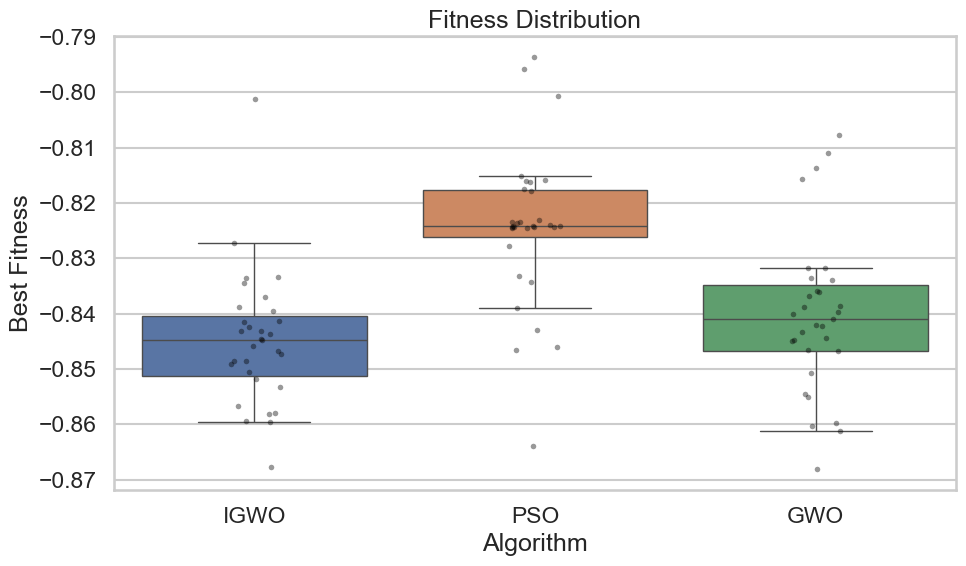

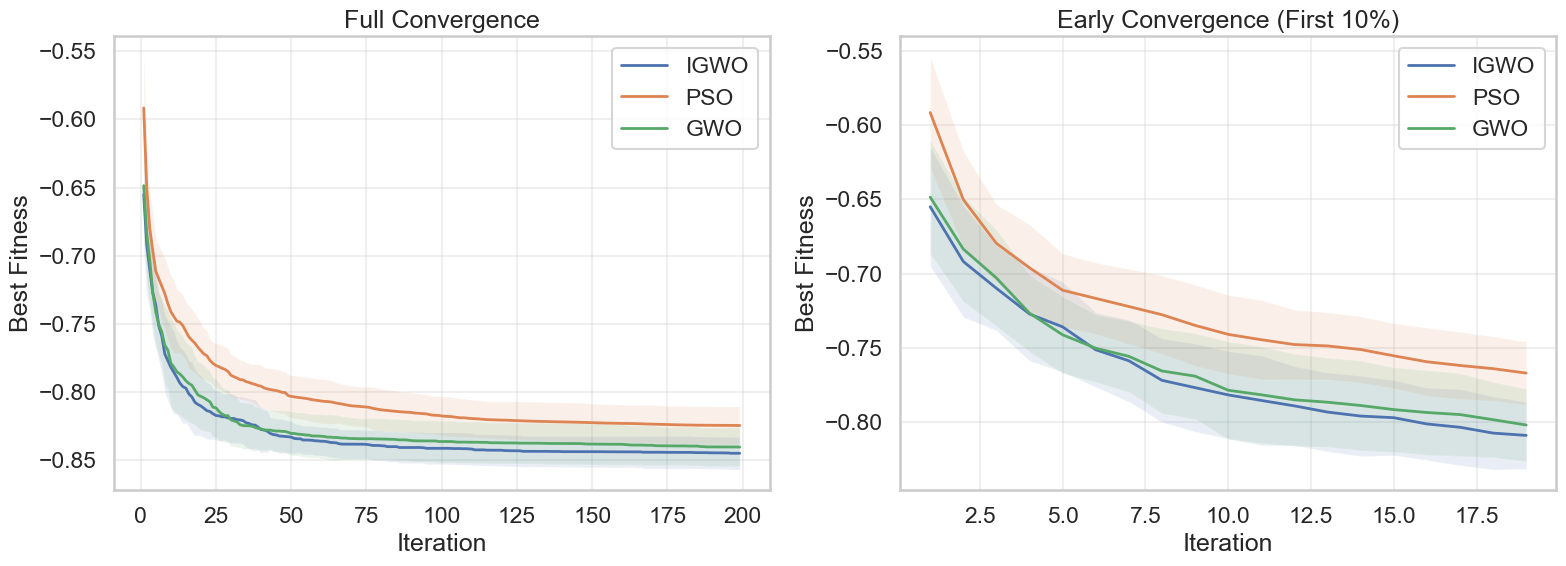

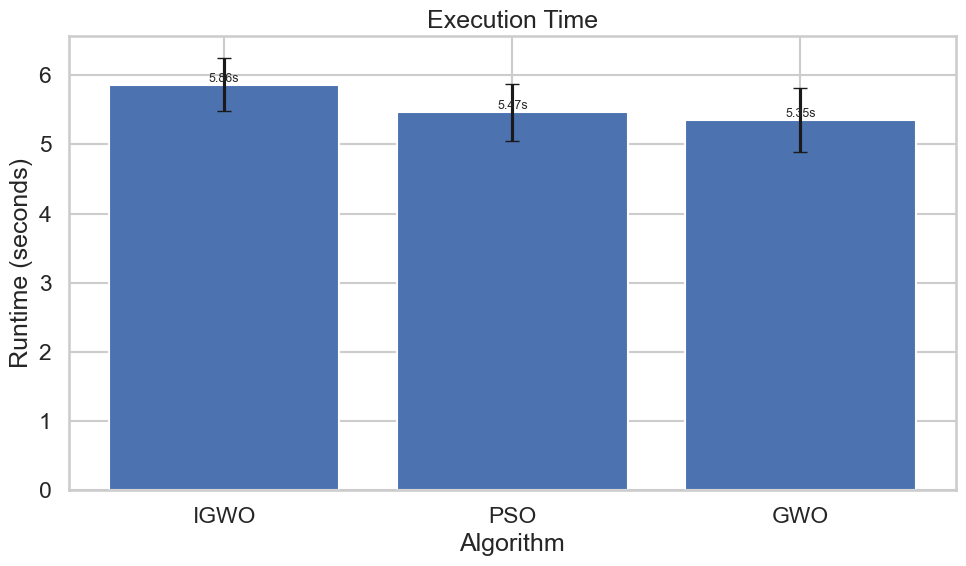

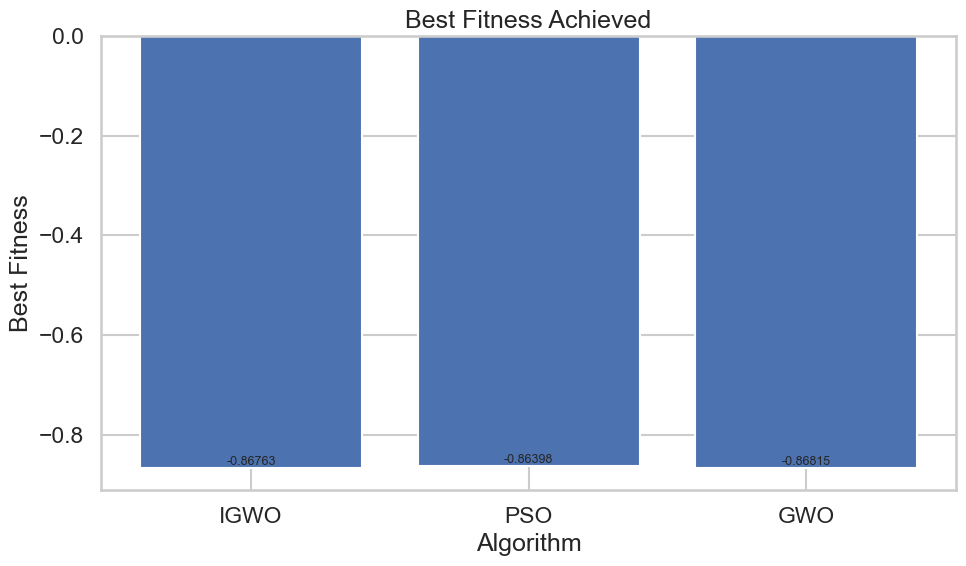

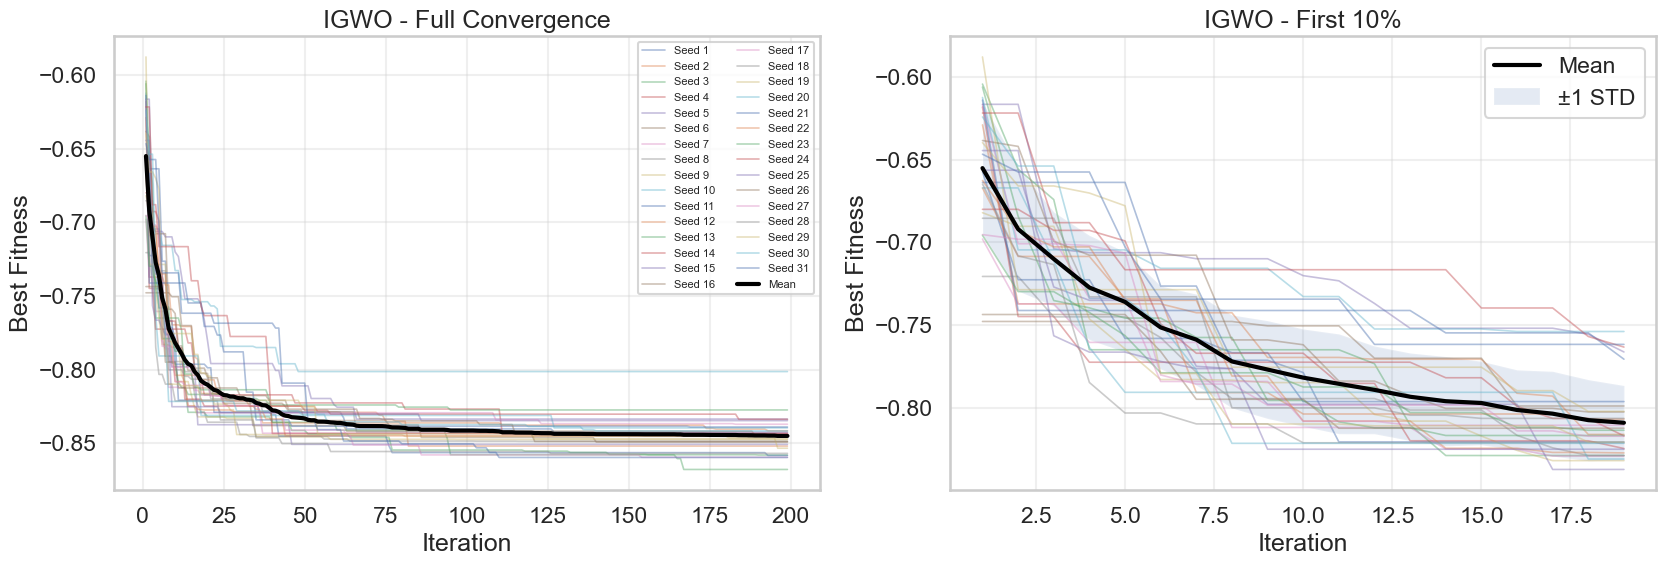

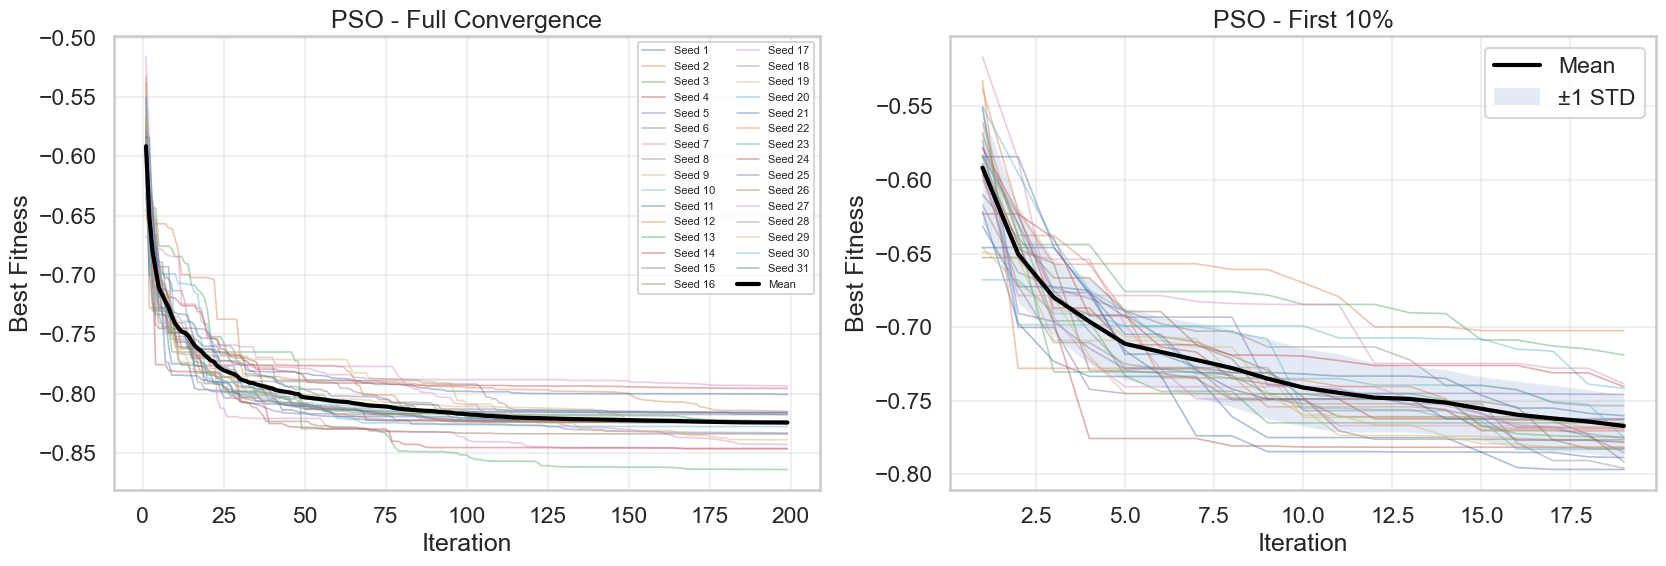

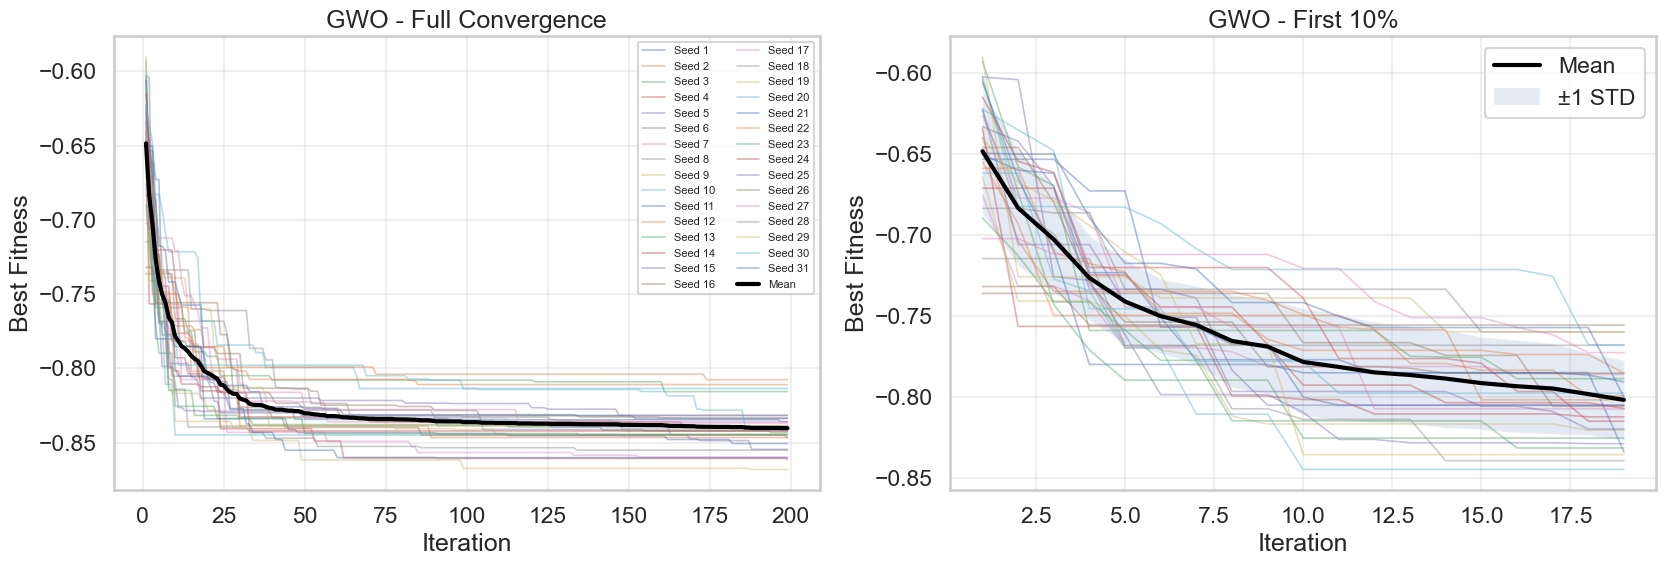

In [89]:
plot_all_results(
    all_results,
    # algorithms=["IGWO", "GWO", "PSO"]
)
plot_individual_convergence(
    all_results,
    # algorithms=["IGWO", "GWO", "PSO"],
    zoom=0.10
)

In [90]:
summary = create_summary_table(all_results)

display(summary.round(5))

summary.to_csv(
    f"results/A_Evening_pressure_algorithm_comparison.csv",
    index=False
)

best_table = create_best_solutions_table(all_results)
display(best_table.round(3))
best_table.to_csv(f"results/A_Evening_pressure_best_solutions.csv", index=False)

,Algorithm,Mean Fitness,Std Fitness,Best Fitness,Worst Fitness,Mean Runtime (s),Std Runtime (s)
0,GWO,-0.84034,0.01438,-0.86815,-0.80770,5.35391,0.46232
1,IGWO,-0.84487,0.01208,-0.86763,-0.80123,5.86409,0.38709
2,PSO,-0.82449,0.01414,-0.86398,-0.79361,5.46750,0.41380


,Algorithm,Best Fitness,x1,y1,p1,h1,c1,z1,x2,y2,...,p3,h3,c3,z3,x4,y4,p4,h4,c4,z4
2,GWO,-0.868,0.253,10.000,0.20,4,1,1,4.469,5.406,...,0.214,4,1,1,0.243,10.000,0.20,4,1,1
0,IGWO,-0.868,4.160,5.423,2.00,4,1,1,9.458,0.387,...,0.200,4,1,1,0.000,10.000,0.20,4,1,1
1,PSO,-0.864,9.268,0.547,0.32,4,1,1,4.502,5.792,...,0.201,4,1,1,0.029,9.993,0.23,4,1,1



IGWO | Best fitness: -0.867635


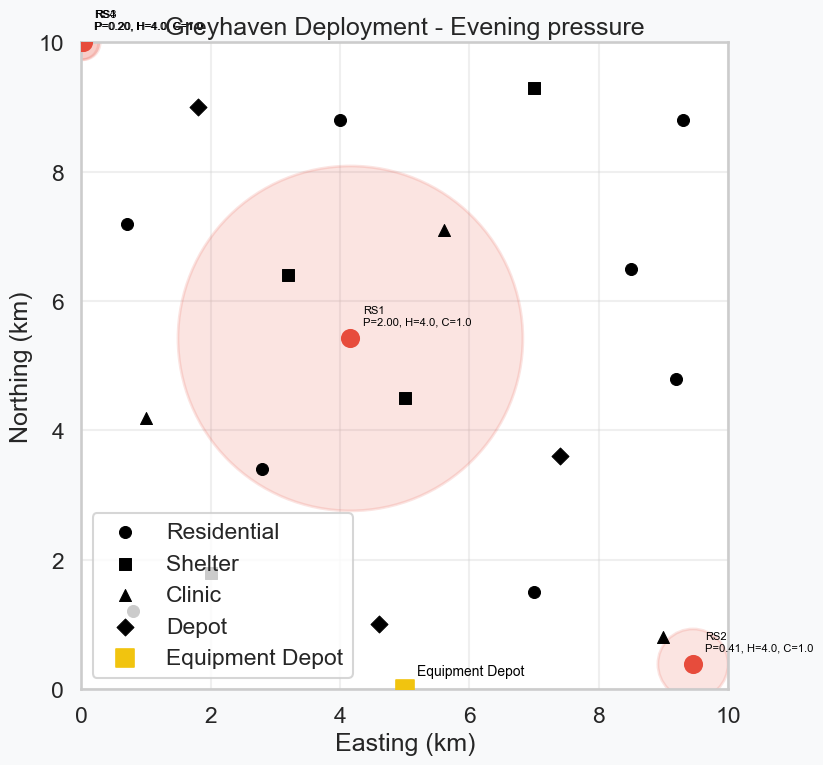


PSO | Best fitness: -0.863984


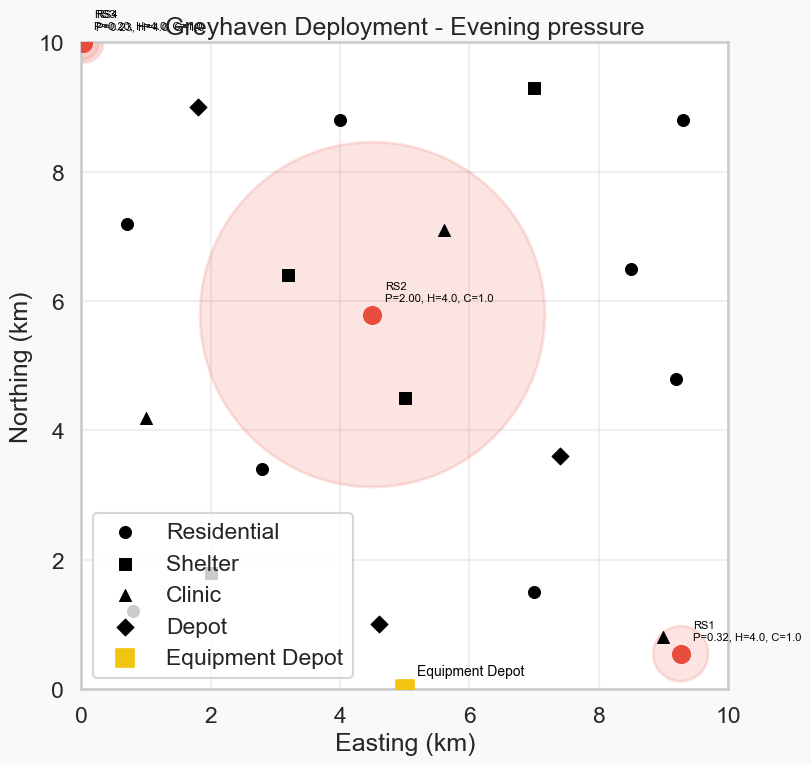


GWO | Best fitness: -0.868148


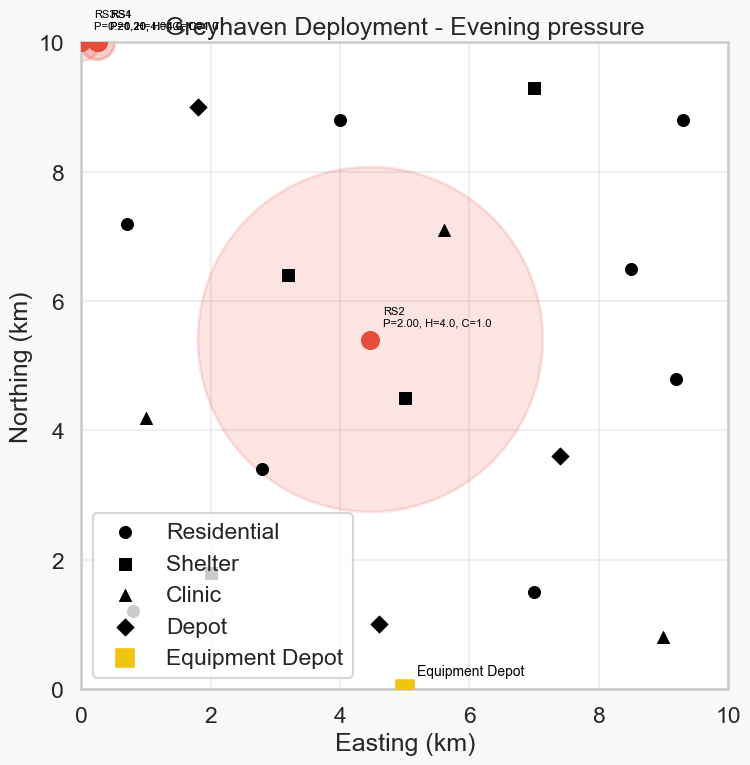

In [91]:
plot_best_deployments(
    all_results,
    situation="Evening pressure",
    assignment="A"
)

## Northern outage

In [92]:
all_results = {}
selected_algorithms = {
    name: algorithms[name]
    for name in ["IGWO", "PSO", "GWO"]
}
for name, optimizer in selected_algorithms.items():

    print(f"\n========== {name} ==========")
    model = optimizer(epoch=10000, pop_size=50)
    all_results[name] = run_experiment(
        "Northern outage",
        model,
        assignment="A"
    )


========== IGWO ==========

Run 1/31 | Fitness: -0.745033 | Epochs: 199 | Time: 5.38s

Run 2/31 | Fitness: -0.761318 | Epochs: 199 | Time: 5.76s

Run 3/31 | Fitness: -0.765097 | Epochs: 199 | Time: 5.43s

Run 4/31 | Fitness: -0.763932 | Epochs: 199 | Time: 5.51s

Run 5/31 | Fitness: -0.750601 | Epochs: 199 | Time: 5.15s

Run 6/31 | Fitness: -0.747152 | Epochs: 199 | Time: 5.17s

Run 7/31 | Fitness: -0.761613 | Epochs: 199 | Time: 5.36s

Run 8/31 | Fitness: -0.758581 | Epochs: 199 | Time: 5.31s

Run 9/31 | Fitness: -0.742349 | Epochs: 199 | Time: 5.56s

Run 10/31 | Fitness: -0.733493 | Epochs: 199 | Time: 4.84s

Run 11/31 | Fitness: -0.763069 | Epochs: 199 | Time: 4.81s

Run 12/31 | Fitness: -0.755884 | Epochs: 199 | Time: 4.66s

Run 13/31 | Fitness: -0.749245 | Epochs: 199 | Time: 4.76s

Run 14/31 | Fitness: -0.761911 | Epochs: 199 | Time: 4.76s

Run 15/31 | Fitness: -0.762408 | Epochs: 199 | Time: 4.65s

Run 16/31 | Fitness: -0.765589 | Epochs: 199 | Time: 4.61s

Run 17/31 | Fitness:

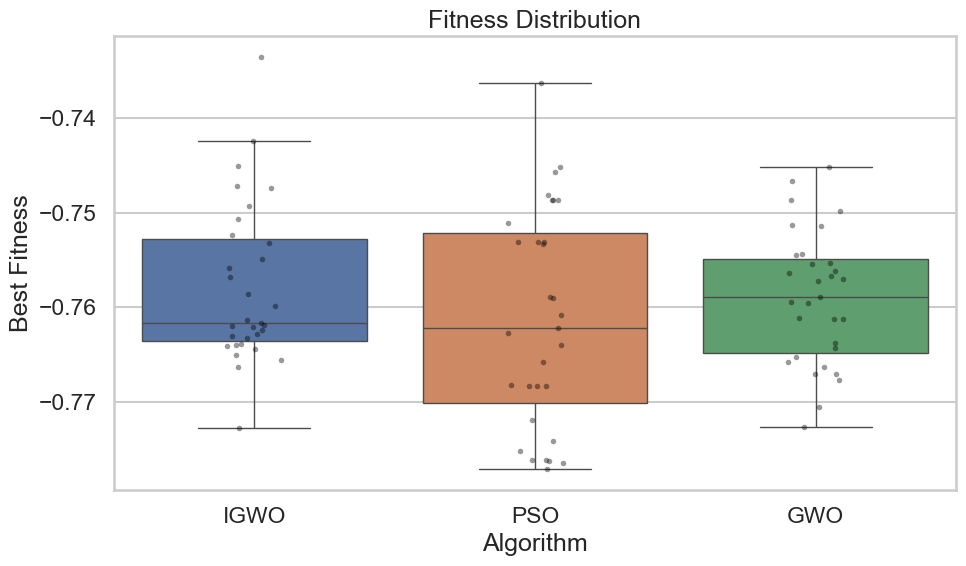

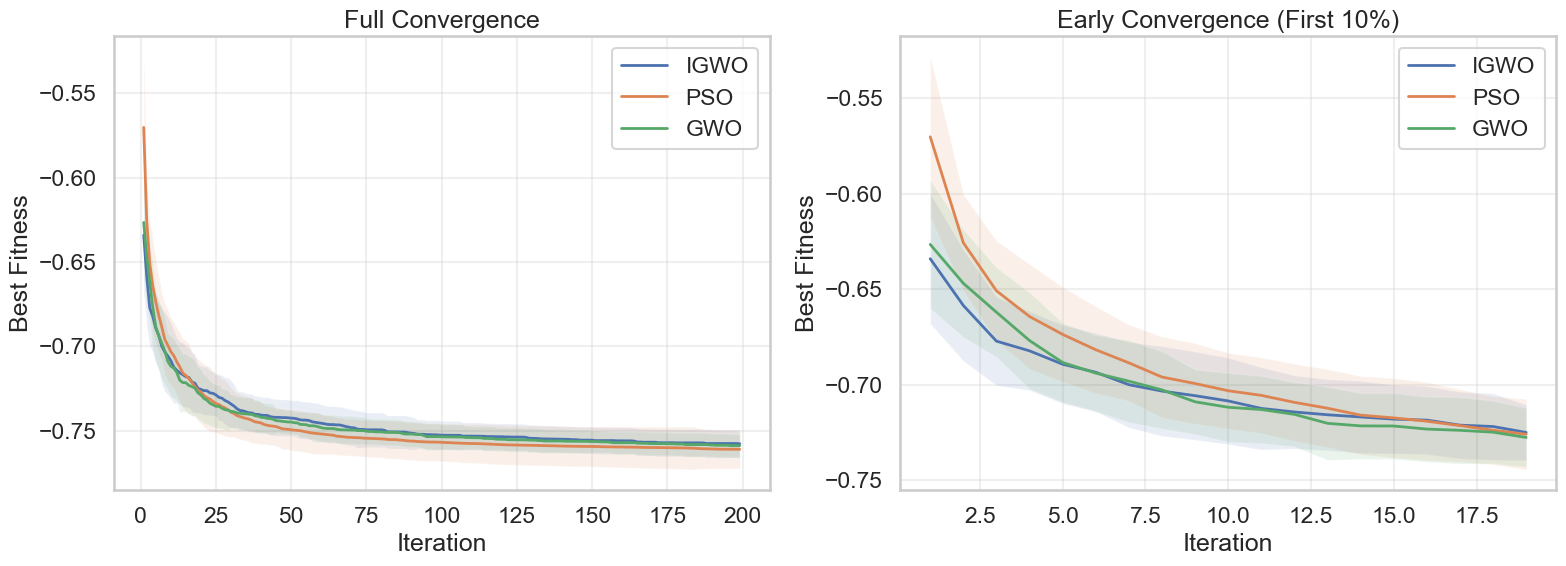

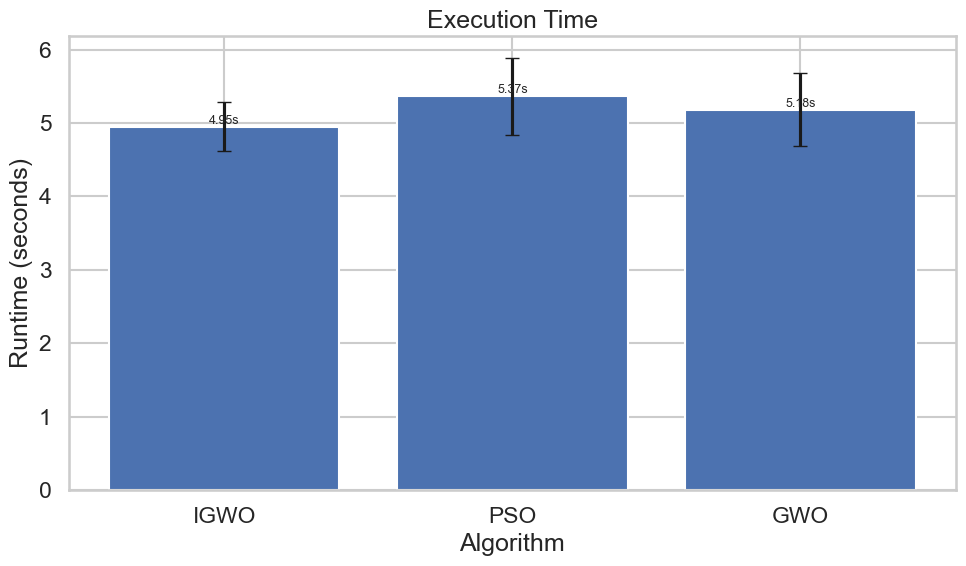

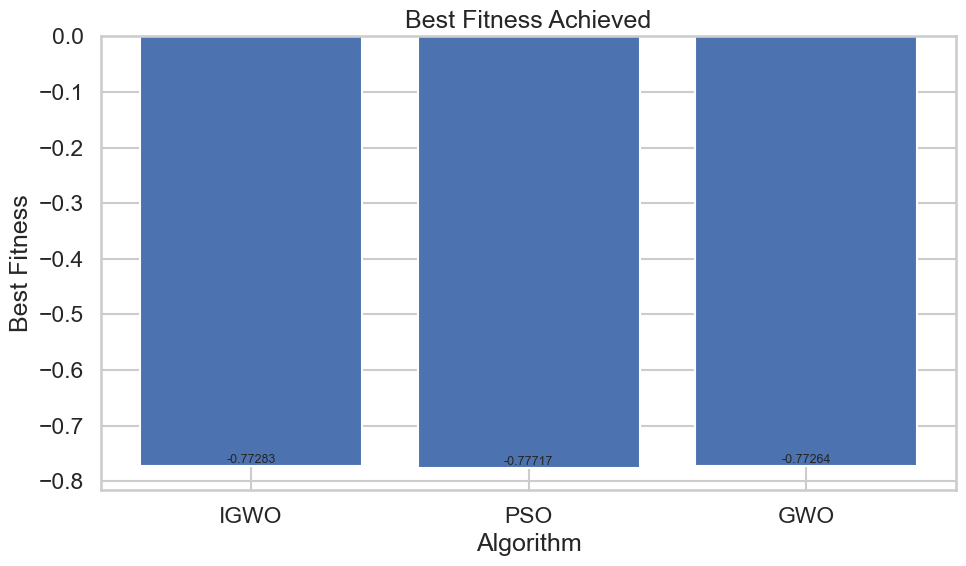

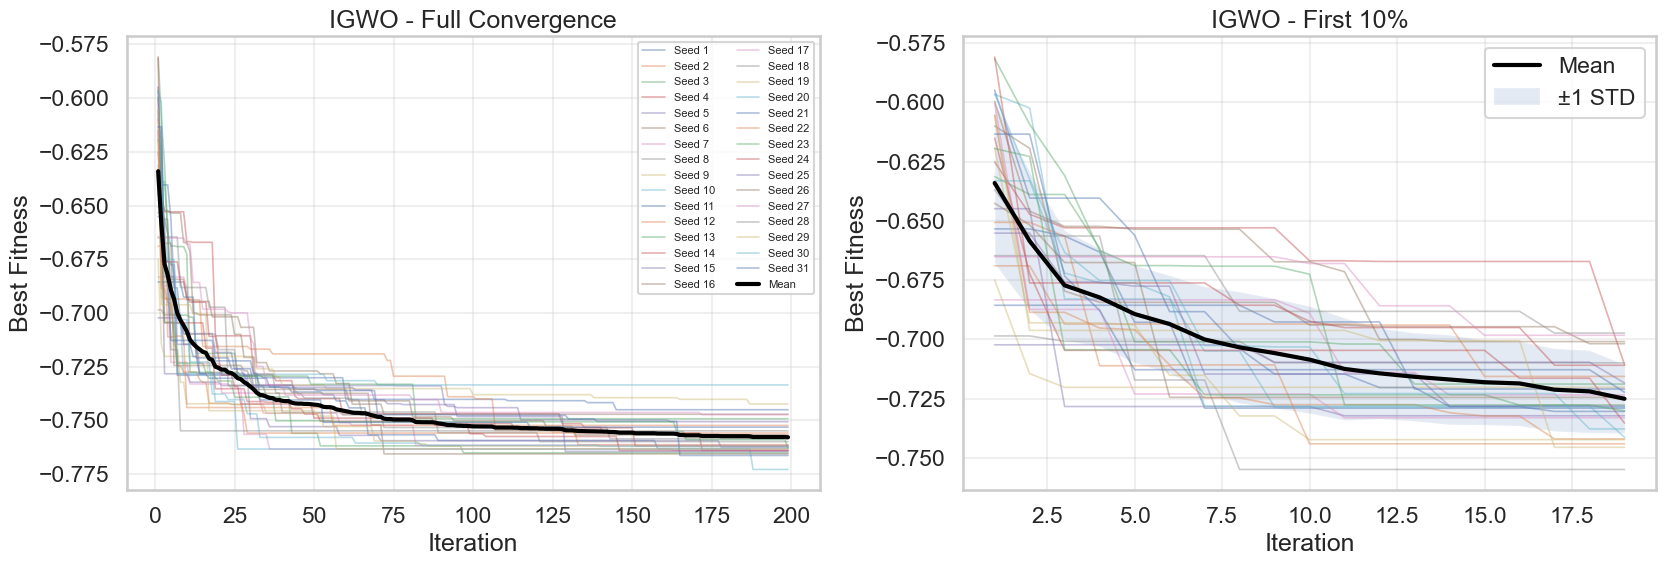

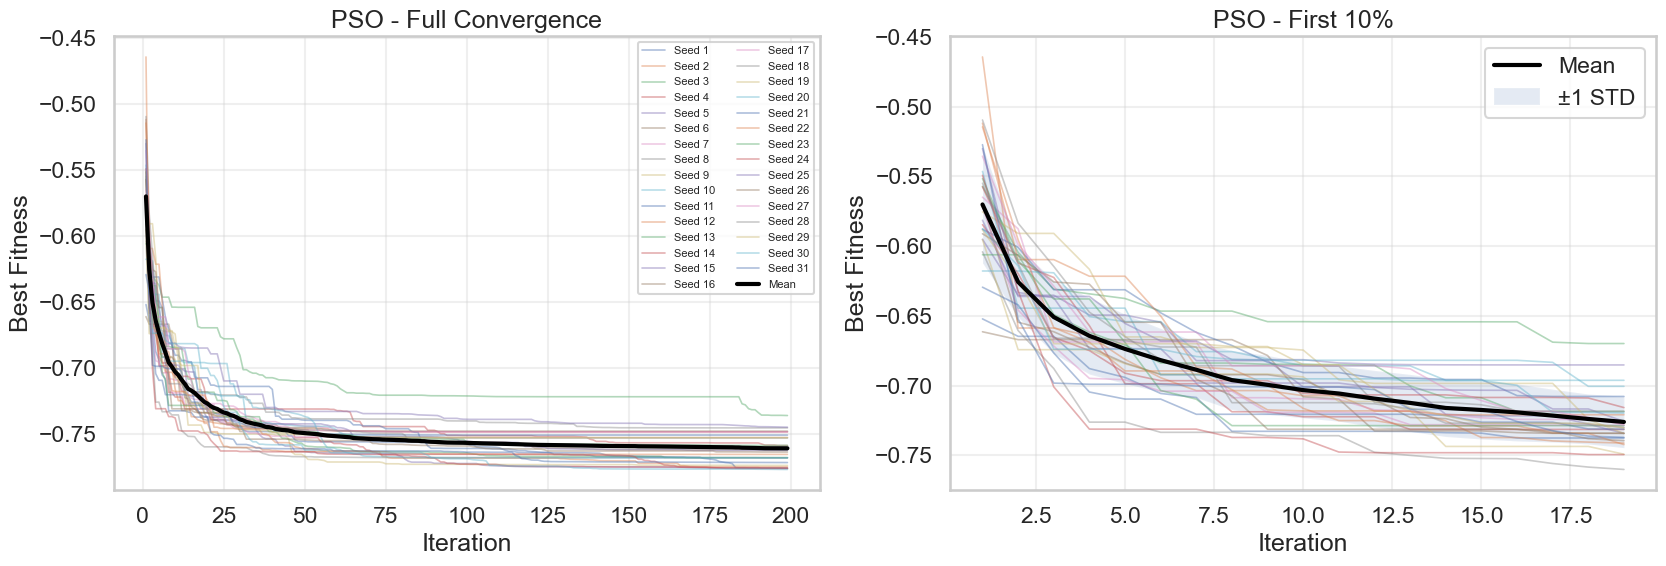

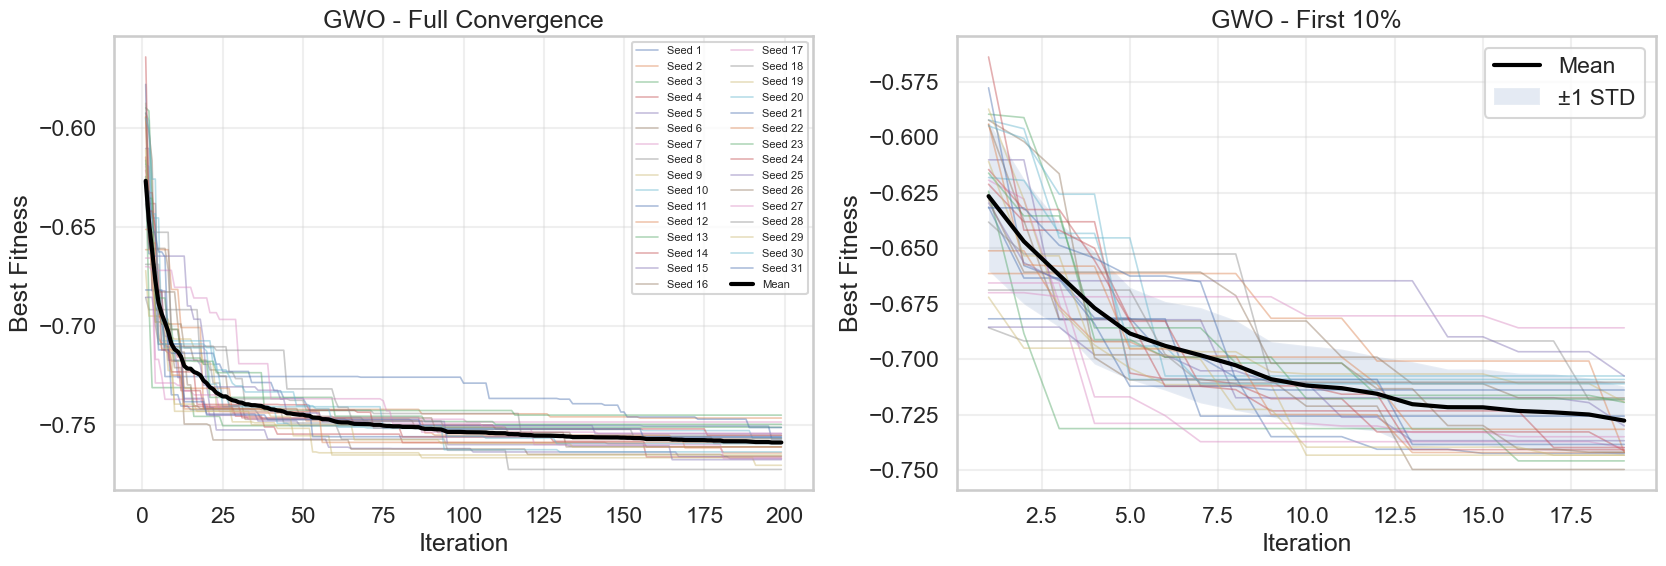

In [93]:
plot_all_results(
    all_results,
    # algorithms=["IGWO", "GWO", "PSO"]
)
plot_individual_convergence(
    all_results,
    # algorithms=["IGWO", "GWO", "PSO"],
    zoom=0.10
)

In [94]:
summary = create_summary_table(all_results)

display(summary.round(5))

summary.to_csv(
    f"results/A_Northern_outage_algorithm_comparison.csv",
    index=False
)

best_table = create_best_solutions_table(all_results)
display(best_table.round(3))
best_table.to_csv(f"results/A_Northern_outage_best_solutions.csv", index=False)

,Algorithm,Mean Fitness,Std Fitness,Best Fitness,Worst Fitness,Mean Runtime (s),Std Runtime (s)
0,PSO,-0.76113,0.01156,-0.77717,-0.73628,5.36535,0.52229
1,IGWO,-0.75785,0.00850,-0.77283,-0.73349,4.95129,0.33215
2,GWO,-0.75897,0.00703,-0.77264,-0.74514,5.18312,0.49798


,Algorithm,Best Fitness,x1,y1,p1,h1,c1,z1,x2,y2,...,p3,h3,c3,z3,x4,y4,p4,h4,c4,z4
1,PSO,-0.777,8.458,0.606,0.772,4,1,1,6.397,7.042,...,1.874,4,1,1,0.000,0.003,0.200,4,1,1
0,IGWO,-0.773,9.413,0.380,0.390,4,1,1,10.000,10.000,...,2.000,4,1,1,10.000,10.000,0.228,4,1,1
2,GWO,-0.773,0.523,2.790,2.000,4,1,1,8.894,0.483,...,2.000,4,1,1,0.519,0.079,0.200,4,1,1



IGWO | Best fitness: -0.772834


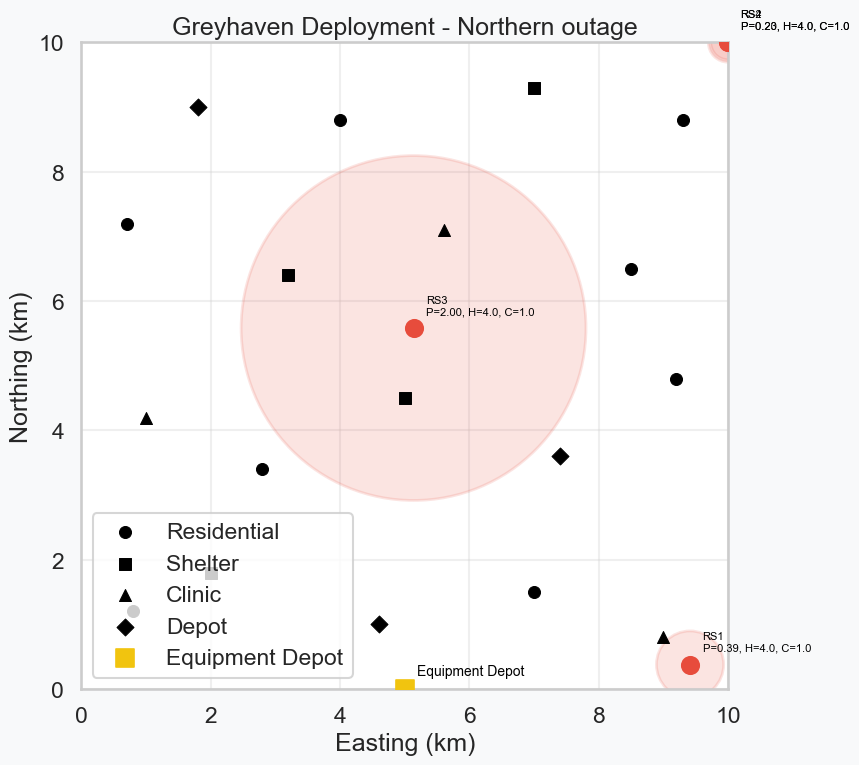


PSO | Best fitness: -0.777175


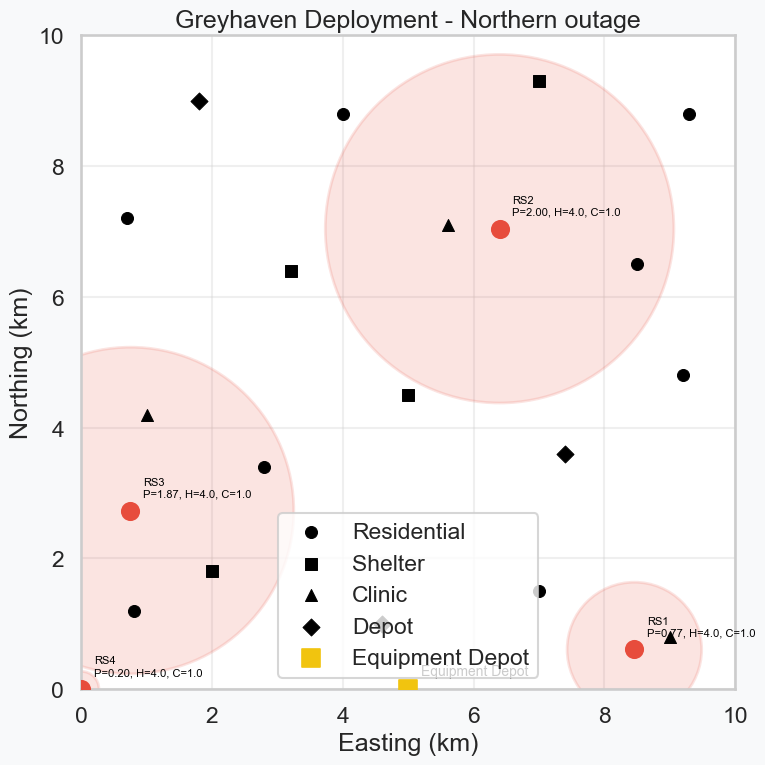


GWO | Best fitness: -0.772640


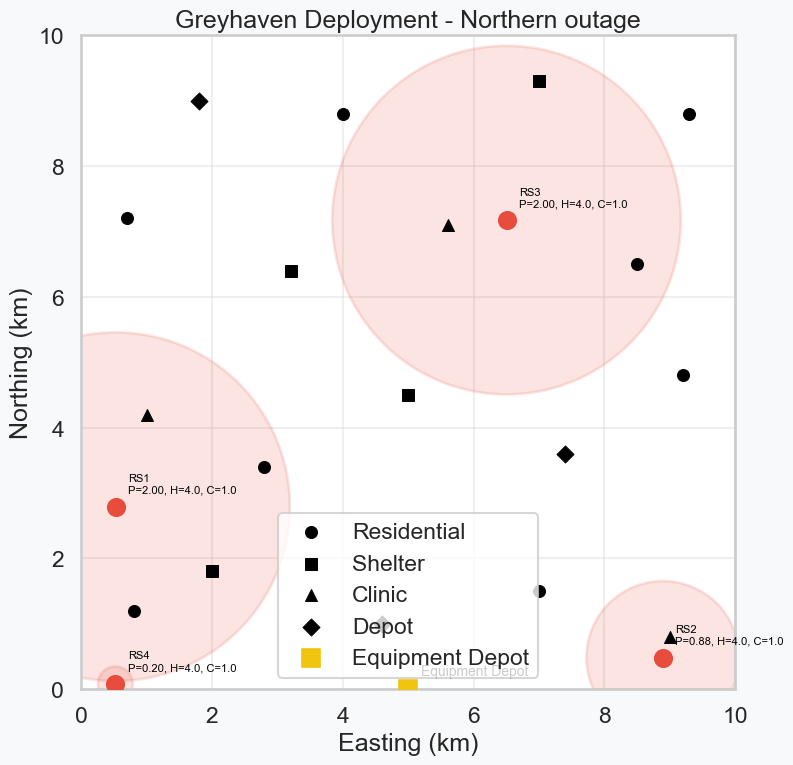

In [95]:
plot_best_deployments(
    all_results,
    situation="Northern outage",
    assignment="A"
)

# Assignment B

## Initial response

In [96]:
all_results = {}
selected_algorithms = {
    name: algorithms[name]
    for name in ["GA", "PSO", "GWO"]
}
for name, optimizer in selected_algorithms.items():

    print(f"\n========== {name} ==========")
    model = optimizer(epoch=10000, pop_size=50)
    all_results[name] = run_experiment(
        "Initial response",
        model,
        assignment="B"
    )


========== GA ==========

Run 1/31 | Fitness: -0.995604 | Epochs: 199 | Time: 11.29s

Run 2/31 | Fitness: -0.995723 | Epochs: 199 | Time: 12.06s

Run 3/31 | Fitness: -0.995701 | Epochs: 199 | Time: 12.20s

Run 4/31 | Fitness: -0.995314 | Epochs: 199 | Time: 11.62s

Run 5/31 | Fitness: -0.995664 | Epochs: 199 | Time: 10.68s

Run 6/31 | Fitness: -0.995685 | Epochs: 199 | Time: 12.93s

Run 7/31 | Fitness: -0.995587 | Epochs: 199 | Time: 12.42s

Run 8/31 | Fitness: -0.995764 | Epochs: 199 | Time: 14.61s

Run 9/31 | Fitness: -0.995727 | Epochs: 199 | Time: 14.10s

Run 10/31 | Fitness: -0.995486 | Epochs: 199 | Time: 13.91s

Run 11/31 | Fitness: -0.995364 | Epochs: 199 | Time: 13.48s

Run 12/31 | Fitness: -0.994684 | Epochs: 199 | Time: 9.88s

Run 13/31 | Fitness: -0.995707 | Epochs: 199 | Time: 9.78s

Run 14/31 | Fitness: -0.995599 | Epochs: 199 | Time: 9.67s

Run 15/31 | Fitness: -0.995756 | Epochs: 199 | Time: 9.81s

Run 16/31 | Fitness: -0.995613 | Epochs: 199 | Time: 9.78s

Run 17/31 |

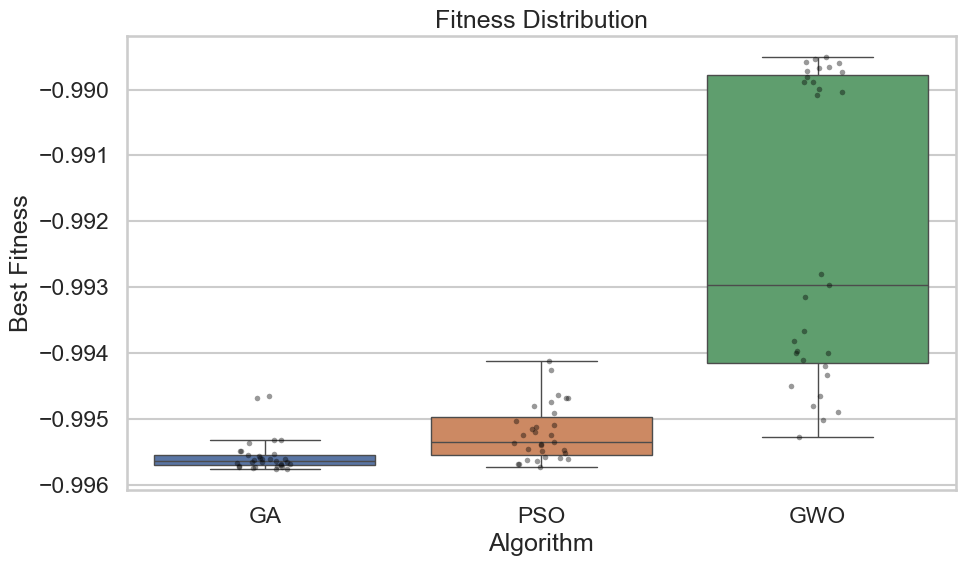

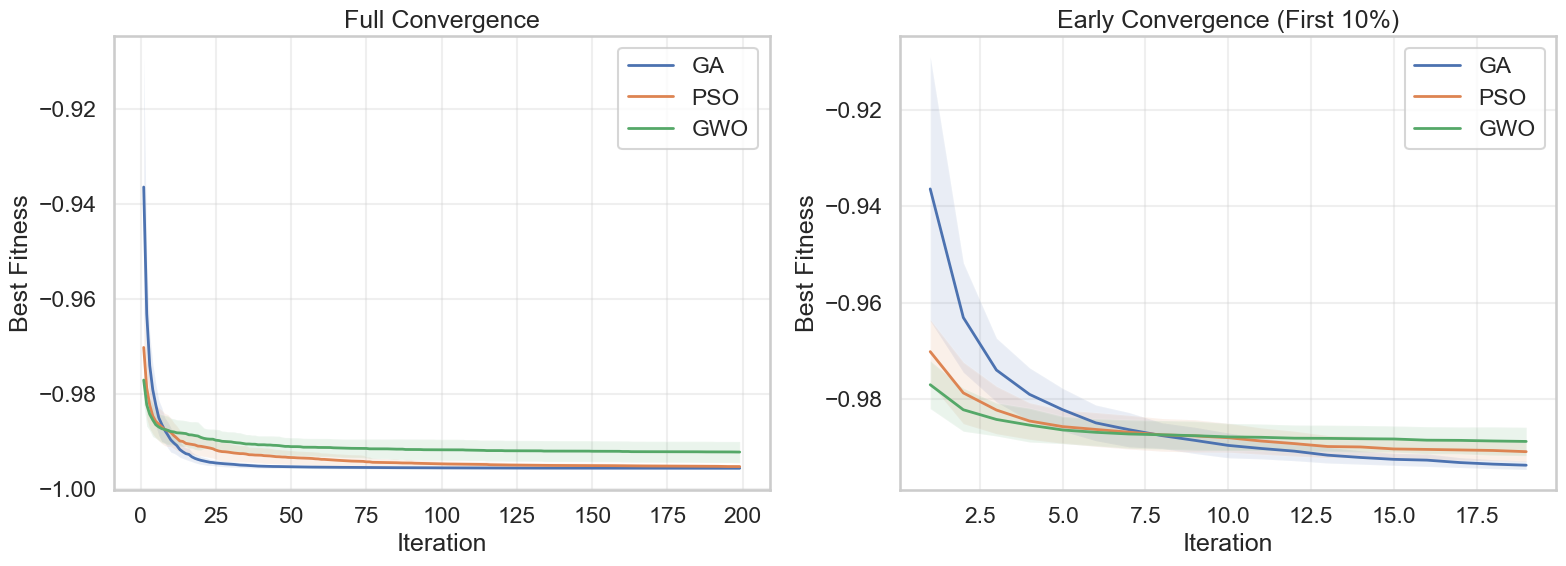

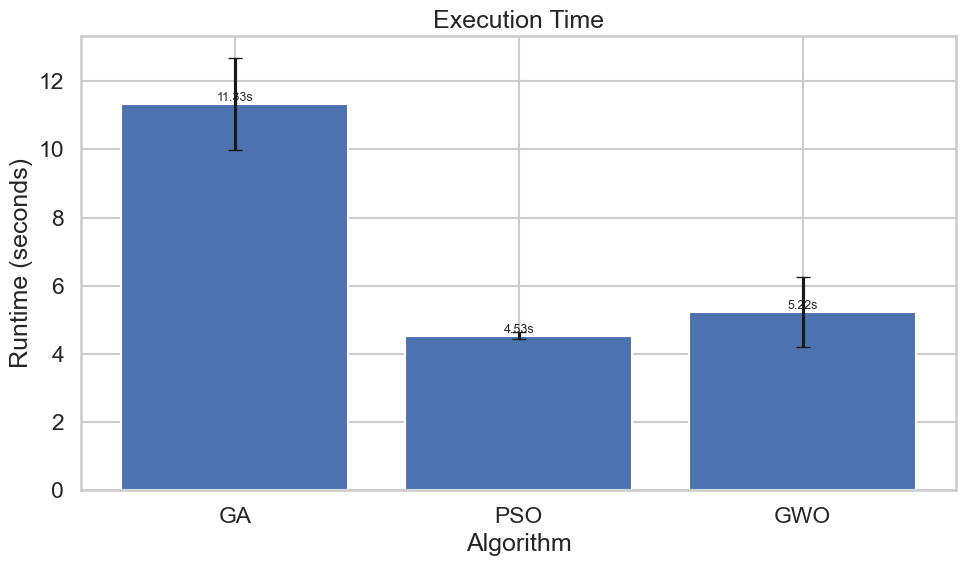

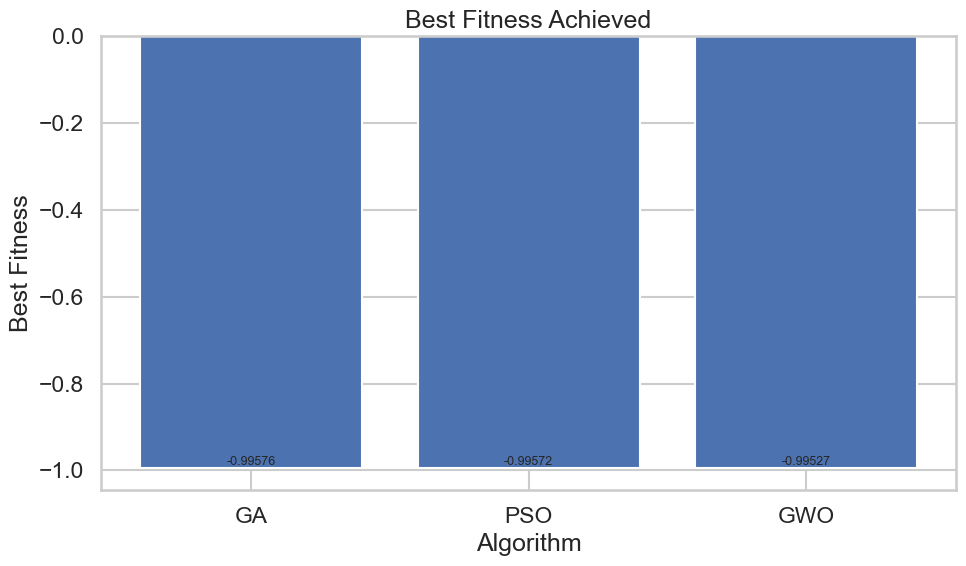

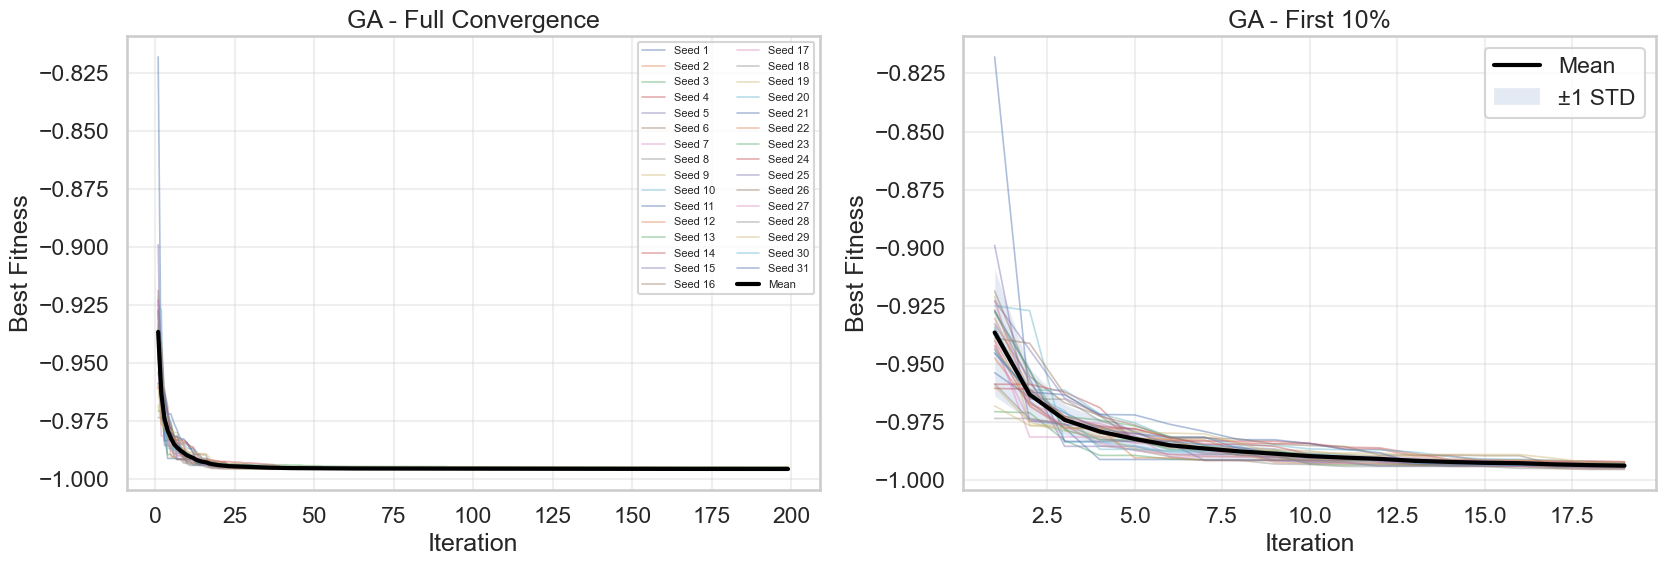

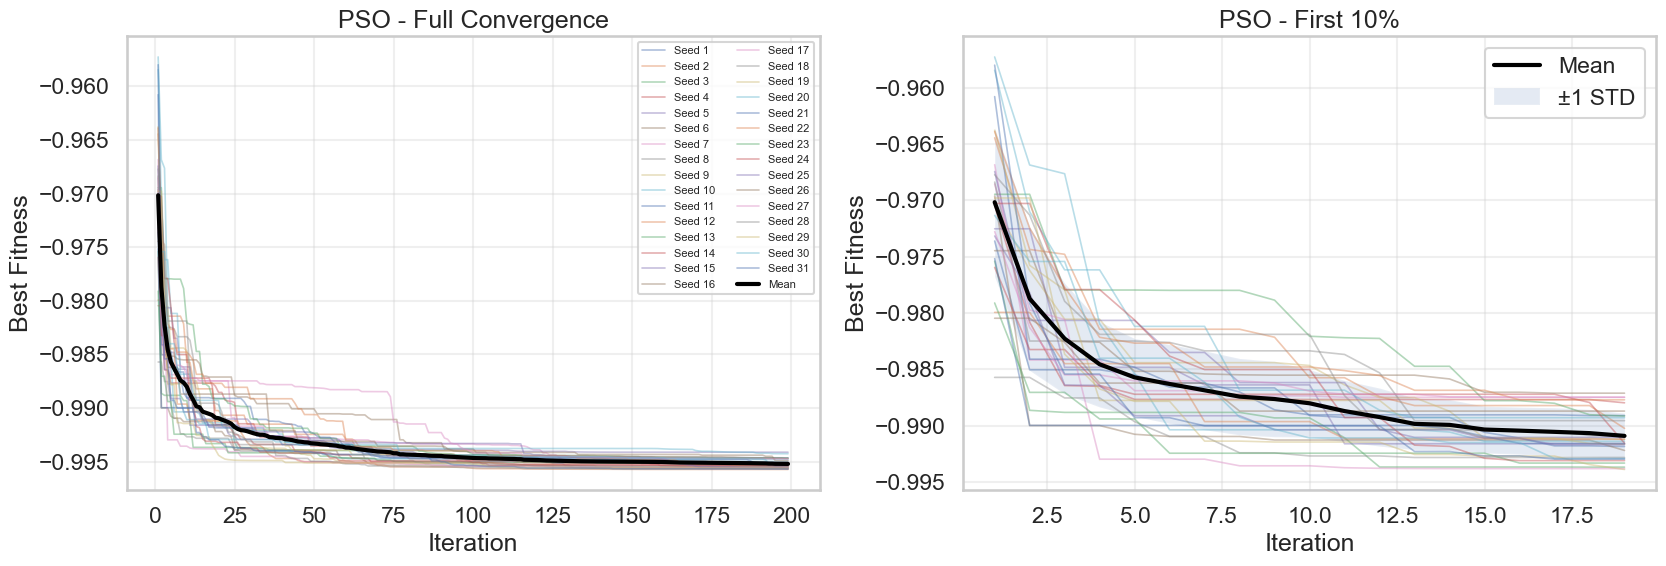

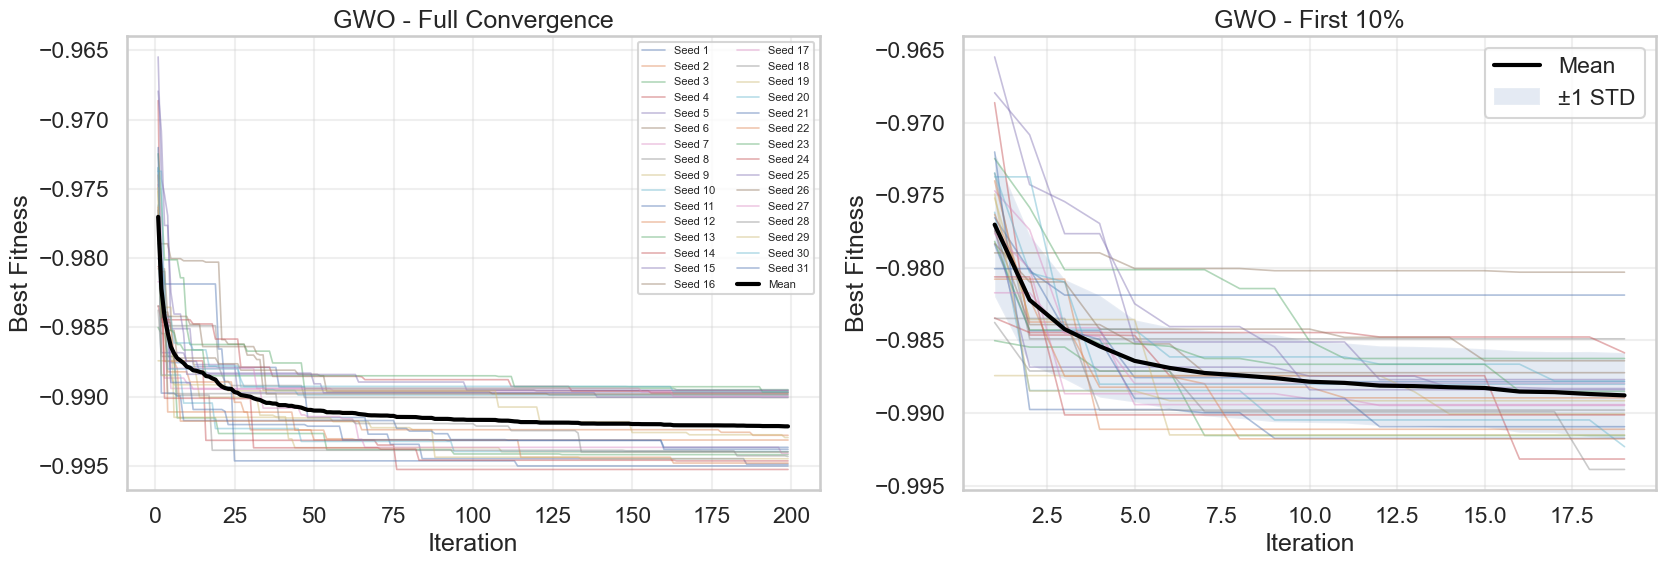

In [97]:
plot_all_results(
    all_results,
    # algorithms=["IGWO", "GWO", "PSO"]
)
plot_individual_convergence(
    all_results,
    # algorithms=["IGWO", "GWO", "PSO"],
    zoom=0.10
)

In [98]:
summary = create_summary_table(all_results)

display(summary.round(5))

summary.to_csv(
    f"results/B_Initial_response_algorithm_comparison.csv",
    index=False
)

best_table = create_best_solutions_table(all_results)
display(best_table.round(3))
best_table.to_csv(f"results/B_Initial_response_best_solutions.csv", index=False)

,Algorithm,Mean Fitness,Std Fitness,Best Fitness,Worst Fitness,Mean Runtime (s),Std Runtime (s)
0,GA,-0.99555,0.00026,-0.99576,-0.99466,11.32805,1.35604
1,PSO,-0.99521,0.00042,-0.99572,-0.99412,4.53251,0.10312
2,GWO,-0.99215,0.00227,-0.99527,-0.98951,5.22409,1.03186


,Algorithm,Best Fitness,x1,y1,p1,h1,c1,z1,x2,y2,...,p3,h3,c3,z3,x4,y4,p4,h4,c4,z4
0,GA,-0.996,2.347,4.145,1.982,4,1,1,5.065,8.100,...,2.000,4,1,1,7.471,2.096,1.996,4,1,1
1,PSO,-0.996,2.458,2.766,0.790,4,1,1,5.766,8.309,...,2.000,4,1,1,2.683,3.874,2.000,4,1,1
2,GWO,-0.995,5.880,7.428,2.000,4,1,1,7.057,1.689,...,1.984,4,1,1,7.693,7.138,1.279,4,1,1



GA | Best fitness: -0.995764


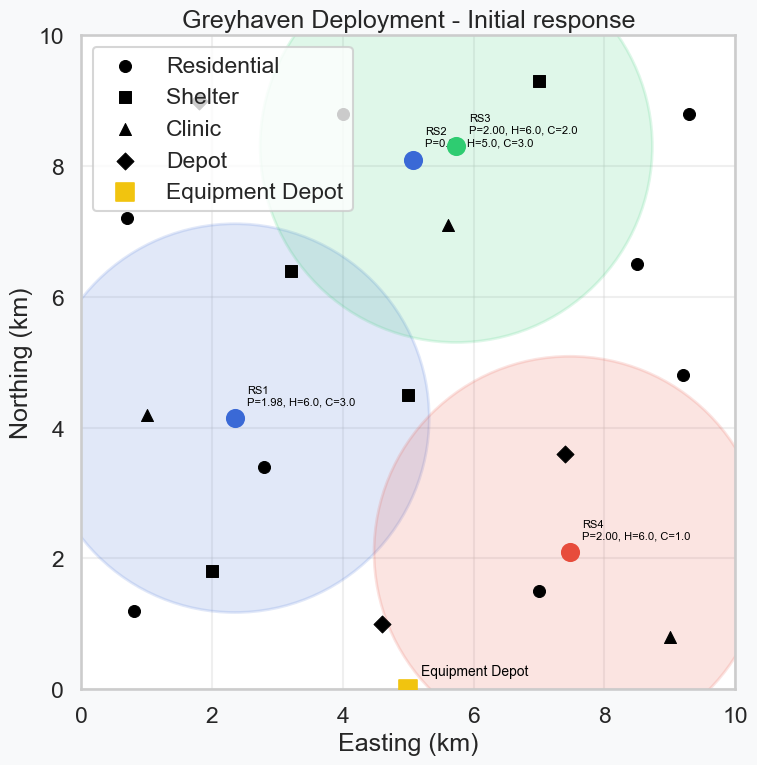


PSO | Best fitness: -0.995724


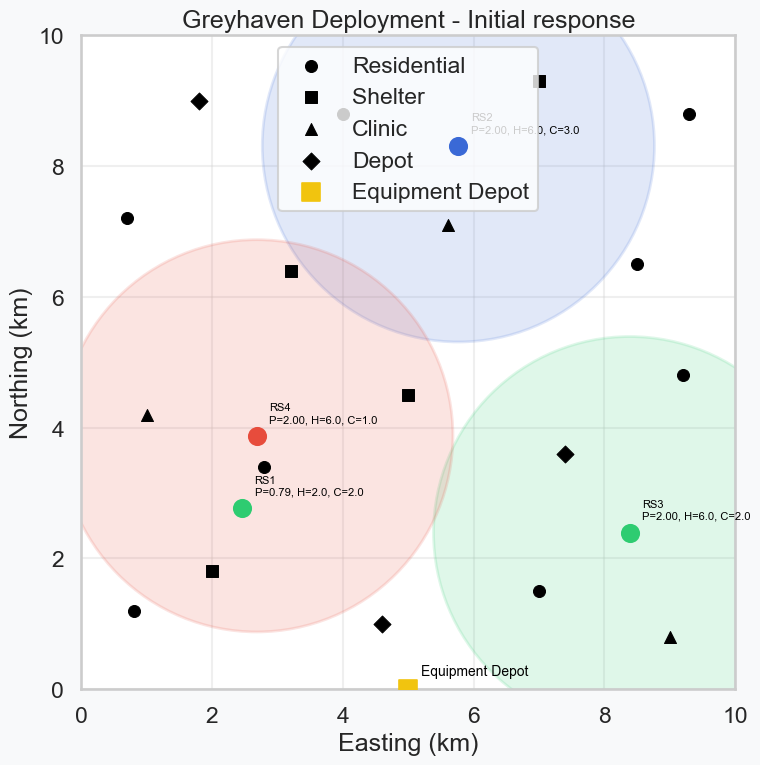


GWO | Best fitness: -0.995267


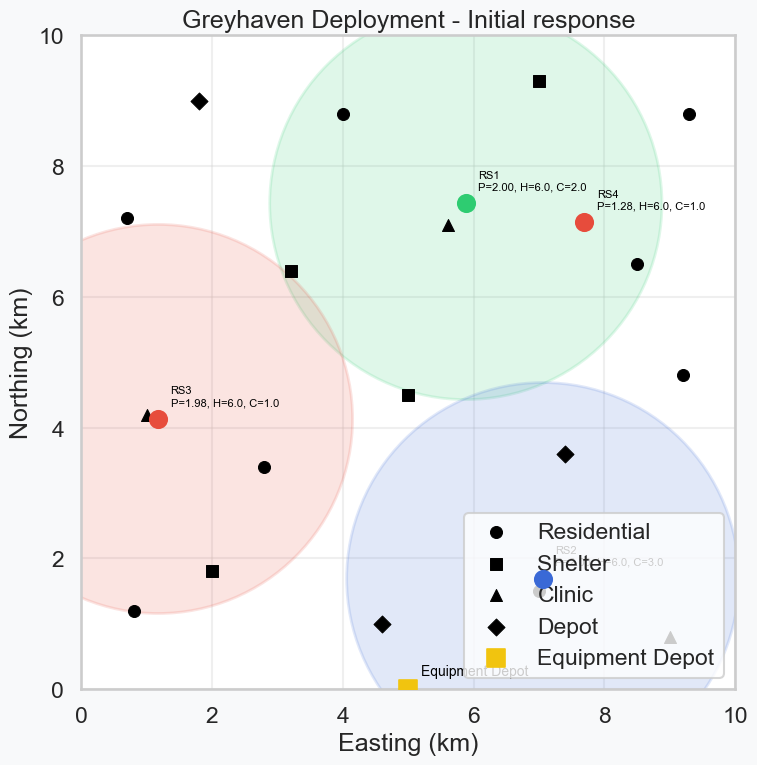

In [99]:
plot_best_deployments(
    all_results,
    situation="Initial response",
    assignment="B"
)

## Evening pressure

In [100]:
all_results = {}
selected_algorithms = {
    name: algorithms[name]
    for name in ["GA", "PSO", "GWO"]
}
for name, optimizer in selected_algorithms.items():

    print(f"\n========== {name} ==========")
    model = optimizer(epoch=10000, pop_size=50)
    all_results[name] = run_experiment(
        "Evening pressure",
        model,
        assignment="B"
    )


========== GA ==========

Run 1/31 | Fitness: -0.990540 | Epochs: 199 | Time: 13.26s

Run 2/31 | Fitness: -0.990595 | Epochs: 199 | Time: 12.73s

Run 3/31 | Fitness: -0.989868 | Epochs: 199 | Time: 12.20s

Run 4/31 | Fitness: -0.990680 | Epochs: 199 | Time: 11.43s

Run 5/31 | Fitness: -0.990617 | Epochs: 199 | Time: 12.17s

Run 6/31 | Fitness: -0.990308 | Epochs: 199 | Time: 15.98s

Run 7/31 | Fitness: -0.990402 | Epochs: 199 | Time: 18.17s

Run 8/31 | Fitness: -0.989814 | Epochs: 199 | Time: 13.61s

Run 9/31 | Fitness: -0.990324 | Epochs: 199 | Time: 13.57s

Run 10/31 | Fitness: -0.990610 | Epochs: 199 | Time: 11.98s

Run 11/31 | Fitness: -0.990743 | Epochs: 199 | Time: 12.19s

Run 12/31 | Fitness: -0.990275 | Epochs: 199 | Time: 15.41s

Run 13/31 | Fitness: -0.990794 | Epochs: 199 | Time: 17.18s

Run 14/31 | Fitness: -0.990462 | Epochs: 199 | Time: 11.36s

Run 15/31 | Fitness: -0.990148 | Epochs: 199 | Time: 12.87s

Run 16/31 | Fitness: -0.990001 | Epochs: 199 | Time: 13.13s

Run 17

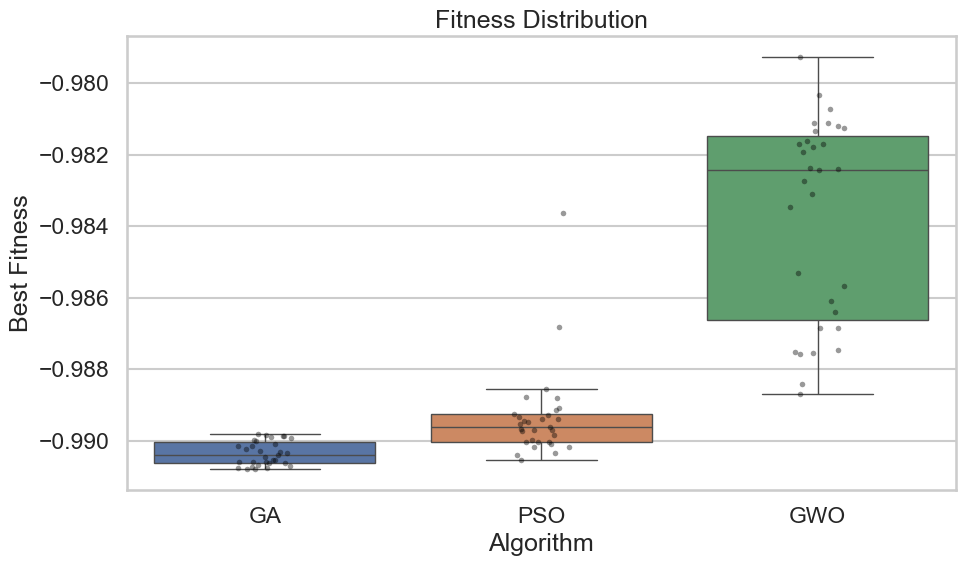

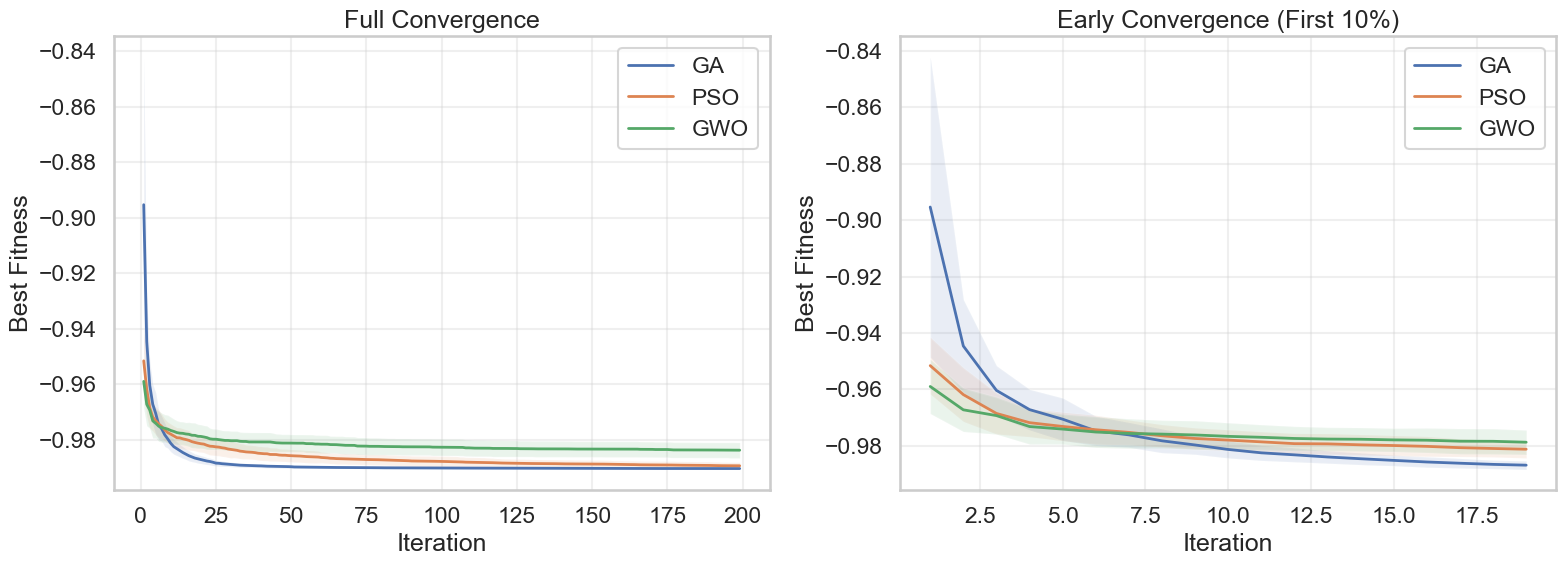

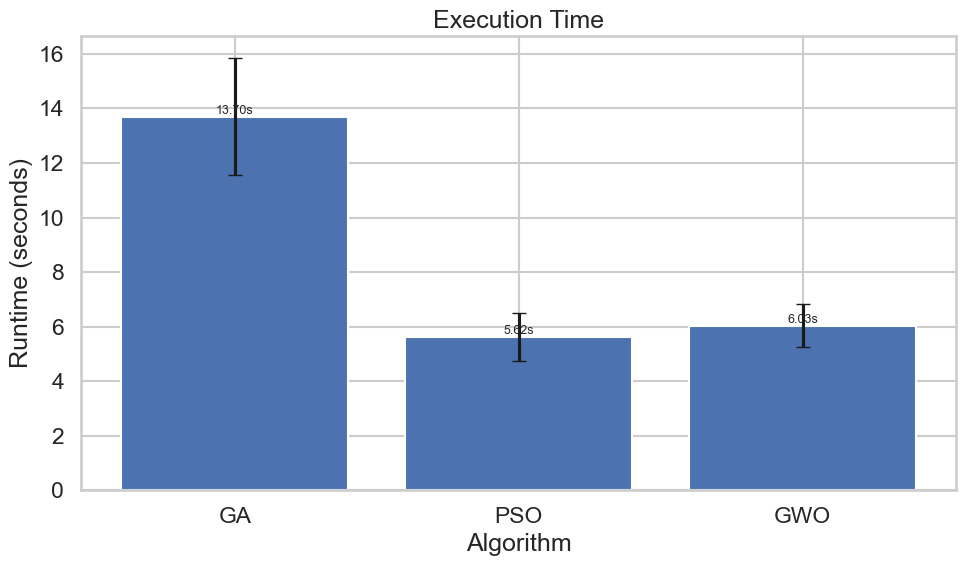

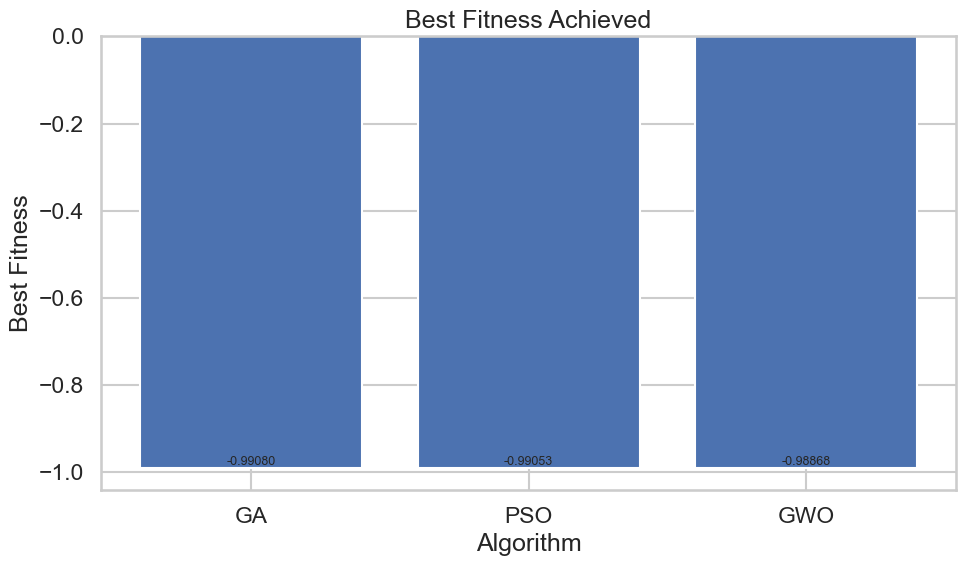

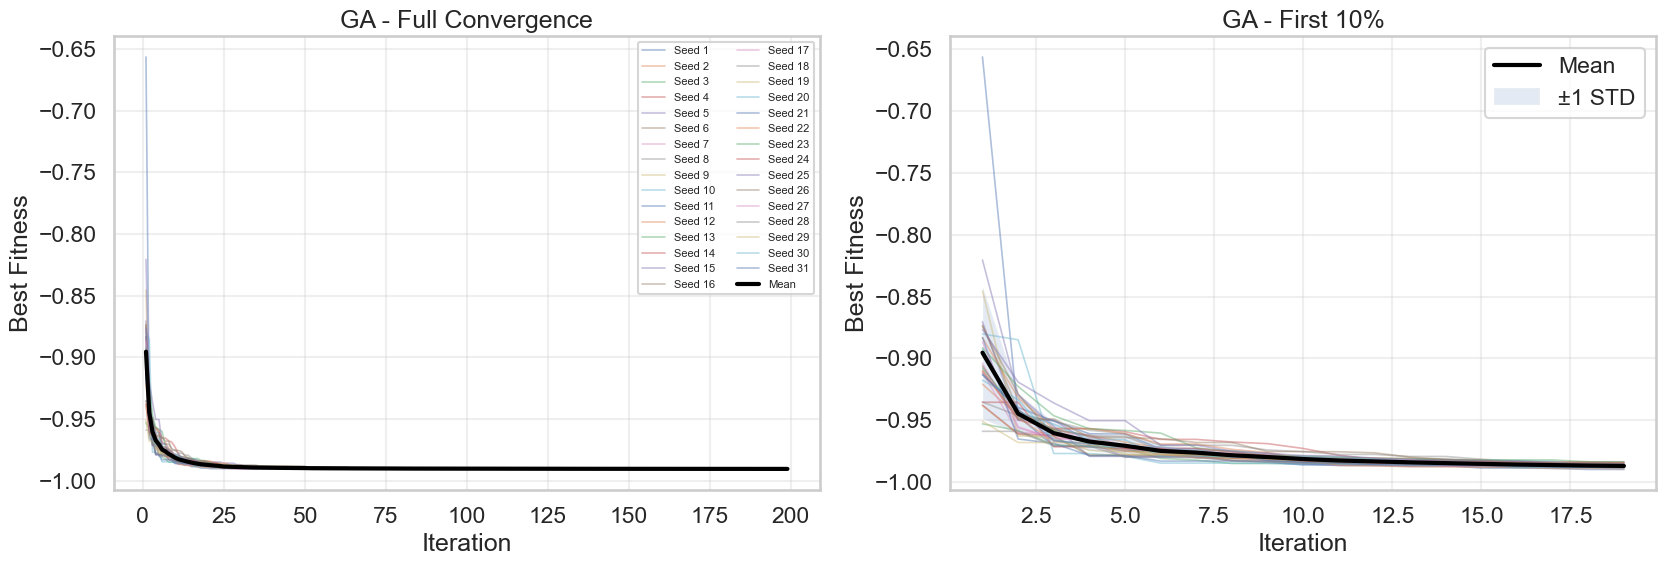

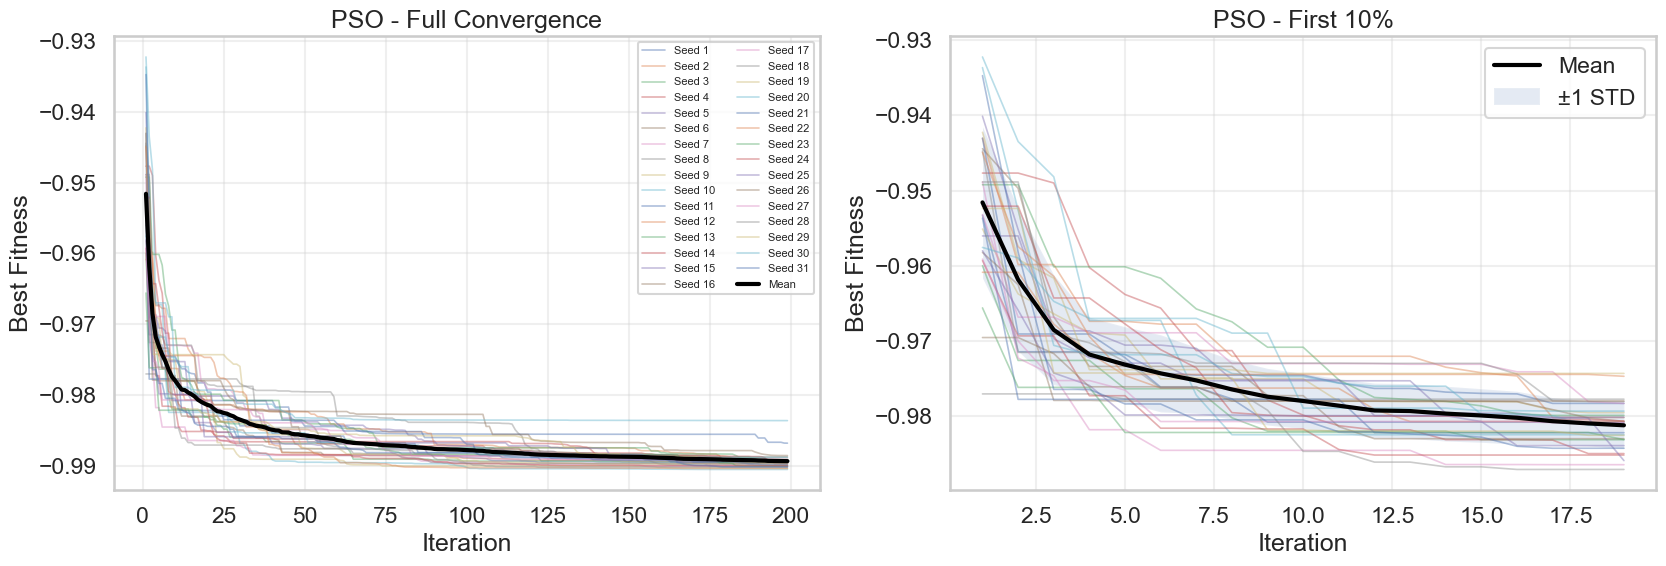

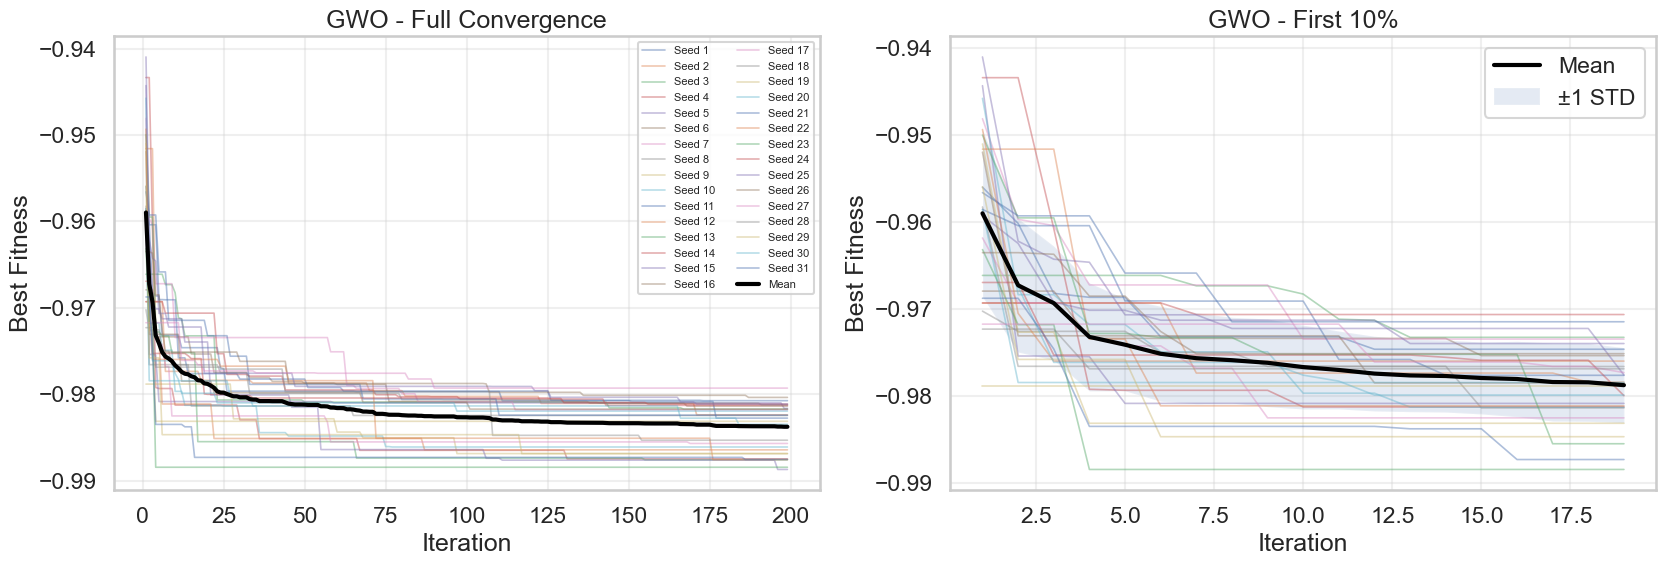

In [101]:
plot_all_results(
    all_results,
    # algorithms=["IGWO", "GWO", "PSO"]
)
plot_individual_convergence(
    all_results,
    # algorithms=["IGWO", "GWO", "PSO"],
    zoom=0.10
)

In [102]:
summary = create_summary_table(all_results)

display(summary.round(5))

summary.to_csv(
    f"results/B_Evening_pressure_algorithm_comparison.csv",
    index=False
)

best_table = create_best_solutions_table(all_results)
display(best_table.round(3))
best_table.to_csv(f"results/B_Evening_pressure_best_solutions.csv", index=False)

,Algorithm,Mean Fitness,Std Fitness,Best Fitness,Worst Fitness,Mean Runtime (s),Std Runtime (s)
0,GA,-0.99035,0.00033,-0.99080,-0.98981,13.70276,2.15147
1,PSO,-0.98935,0.00127,-0.99053,-0.98362,5.62280,0.89007
2,GWO,-0.98374,0.00283,-0.98868,-0.97927,6.02591,0.79472


,Algorithm,Best Fitness,x1,y1,p1,h1,c1,z1,x2,y2,...,p3,h3,c3,z3,x4,y4,p4,h4,c4,z4
0,GA,-0.991,4.986,0.929,0.825,4,1,1,5.823,7.804,...,1.986,4,1,1,3.364,4.513,2.00,4,1,1
1,PSO,-0.991,5.850,7.797,1.989,4,1,1,3.495,4.422,...,1.429,4,1,1,8.517,2.521,2.00,4,1,1
2,GWO,-0.989,2.572,2.515,2.000,4,1,1,8.652,3.510,...,2.000,4,1,1,3.312,9.955,0.39,4,1,1



GA | Best fitness: -0.990797


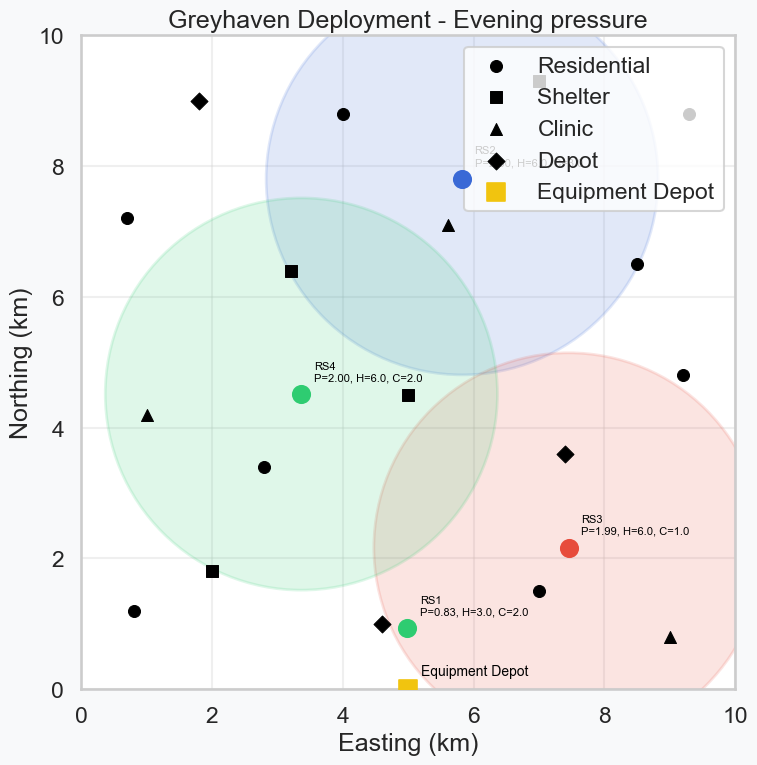


PSO | Best fitness: -0.990525


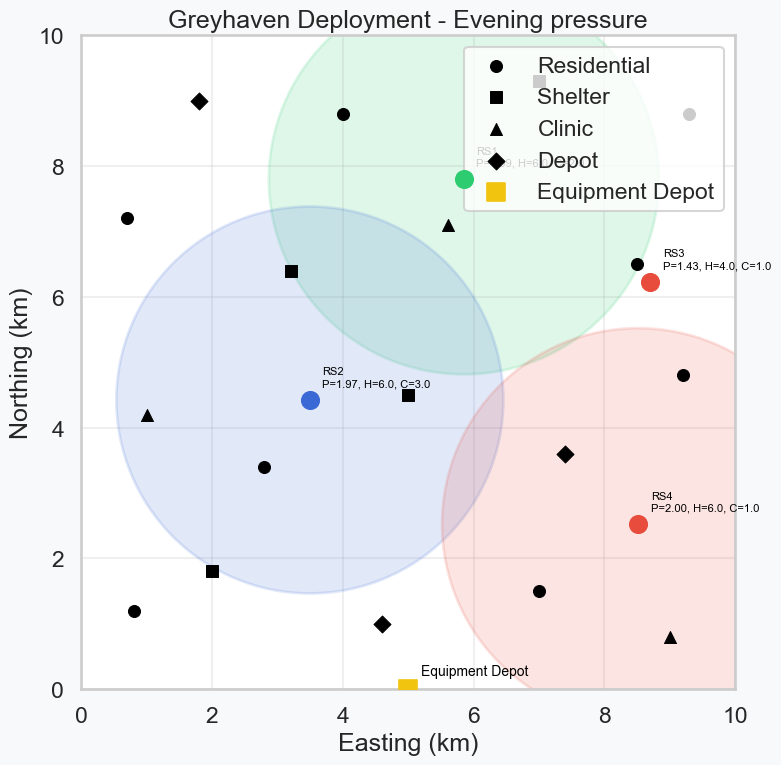


GWO | Best fitness: -0.988677


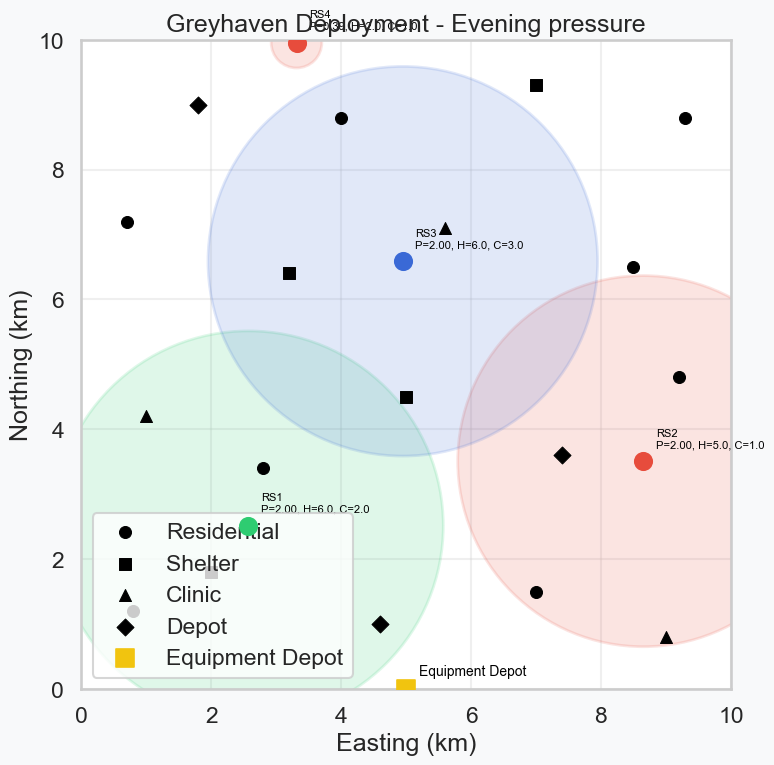

In [103]:
plot_best_deployments(
    all_results,
    situation="Evening pressure",
    assignment="B"
)

## Northern outage

In [104]:
all_results = {}
selected_algorithms = {
    name: algorithms[name]
    for name in ["GA", "PSO", "GWO"]
}
for name, optimizer in selected_algorithms.items():

    print(f"\n========== {name} ==========")
    model = optimizer(epoch=10000, pop_size=50)
    all_results[name] = run_experiment(
        "Northern outage",
        model,
        assignment="B"
    )


========== GA ==========

Run 1/31 | Fitness: -0.984578 | Epochs: 199 | Time: 13.65s

Run 2/31 | Fitness: -0.984823 | Epochs: 199 | Time: 12.13s

Run 3/31 | Fitness: -0.979070 | Epochs: 199 | Time: 11.59s

Run 4/31 | Fitness: -0.984756 | Epochs: 199 | Time: 12.40s

Run 5/31 | Fitness: -0.984582 | Epochs: 199 | Time: 17.15s

Run 6/31 | Fitness: -0.984868 | Epochs: 199 | Time: 17.08s

Run 7/31 | Fitness: -0.984664 | Epochs: 199 | Time: 17.34s

Run 8/31 | Fitness: -0.984645 | Epochs: 199 | Time: 17.14s

Run 9/31 | Fitness: -0.984875 | Epochs: 199 | Time: 16.69s

Run 10/31 | Fitness: -0.984517 | Epochs: 199 | Time: 16.95s

Run 11/31 | Fitness: -0.984685 | Epochs: 199 | Time: 17.01s

Run 12/31 | Fitness: -0.985566 | Epochs: 199 | Time: 17.00s

Run 13/31 | Fitness: -0.984794 | Epochs: 199 | Time: 16.75s

Run 14/31 | Fitness: -0.984885 | Epochs: 199 | Time: 16.82s

Run 15/31 | Fitness: -0.984913 | Epochs: 199 | Time: 17.20s

Run 16/31 | Fitness: -0.984711 | Epochs: 199 | Time: 13.81s

Run 17

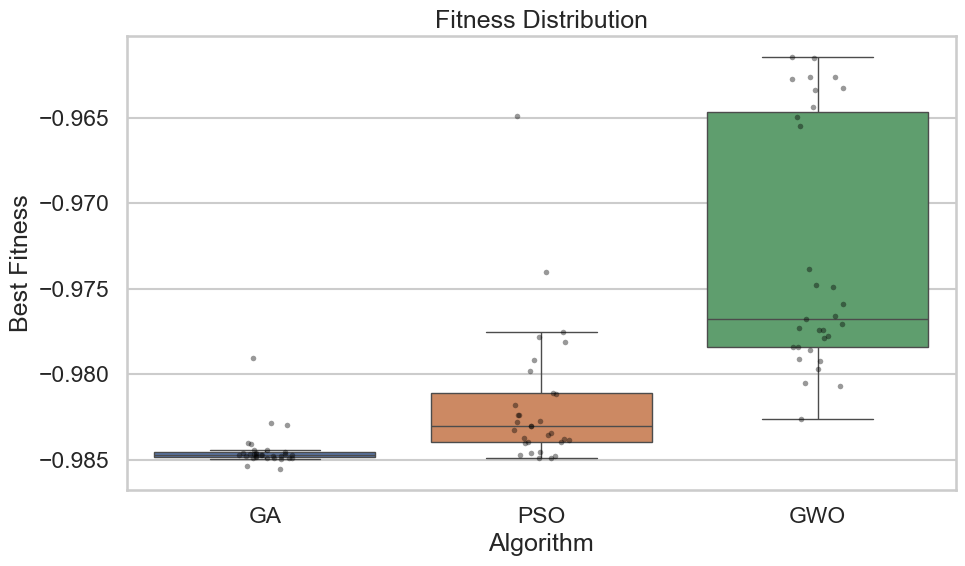

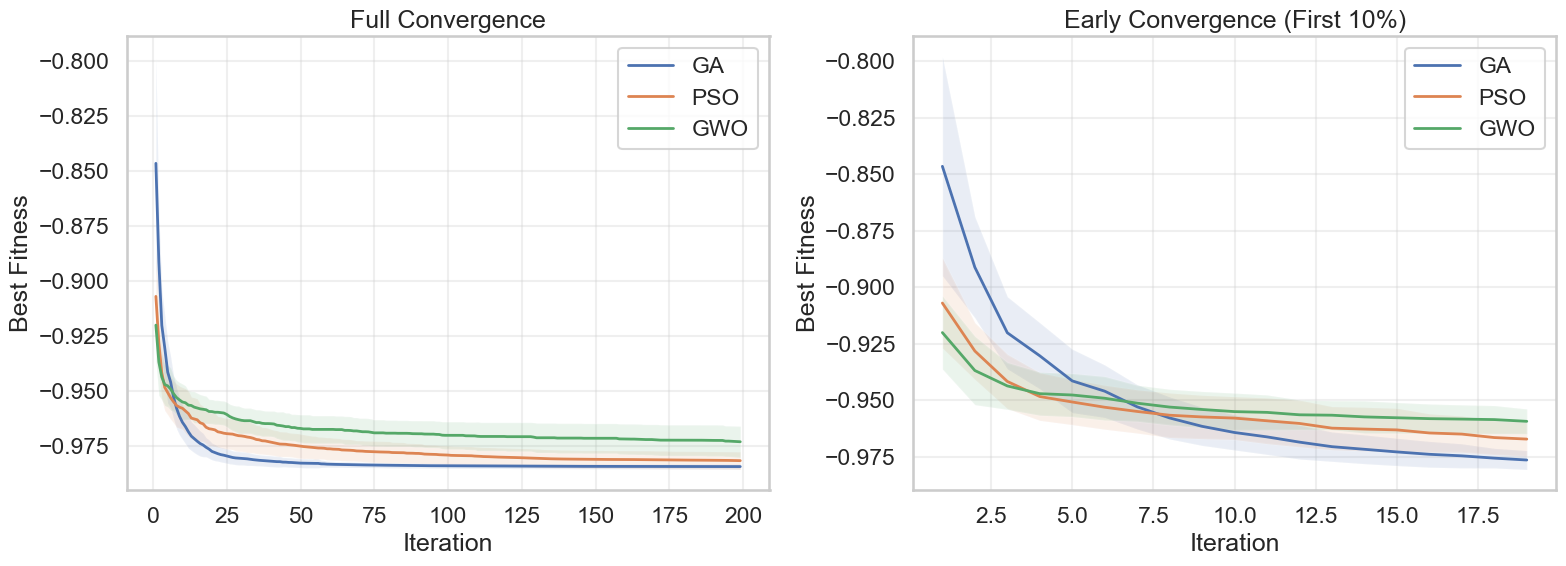

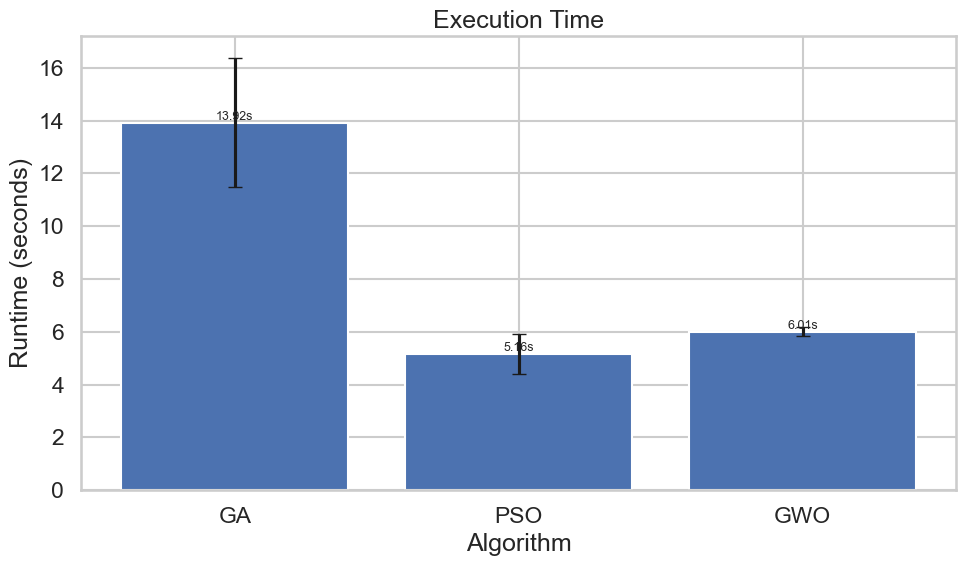

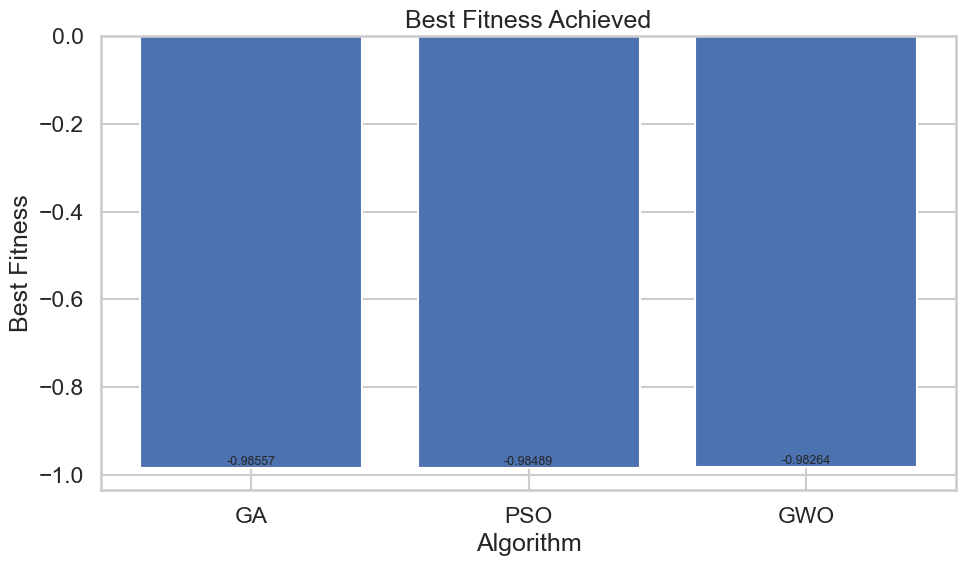

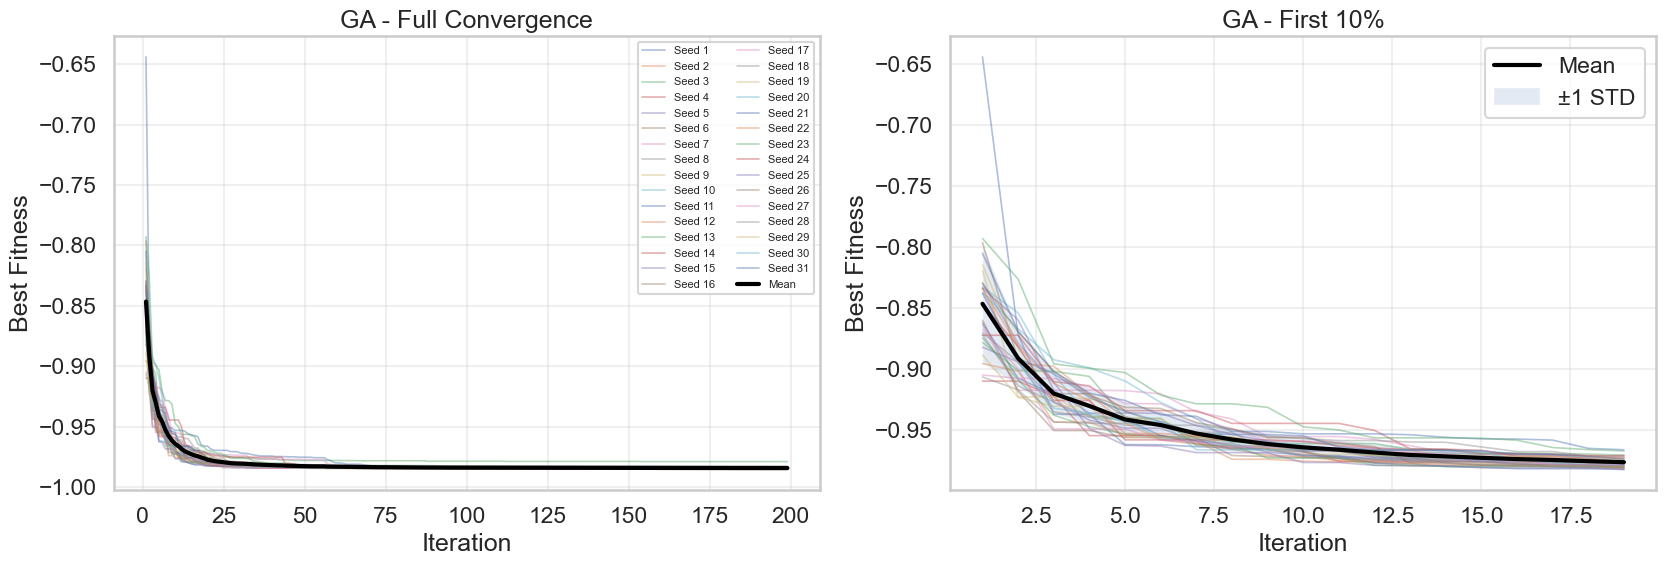

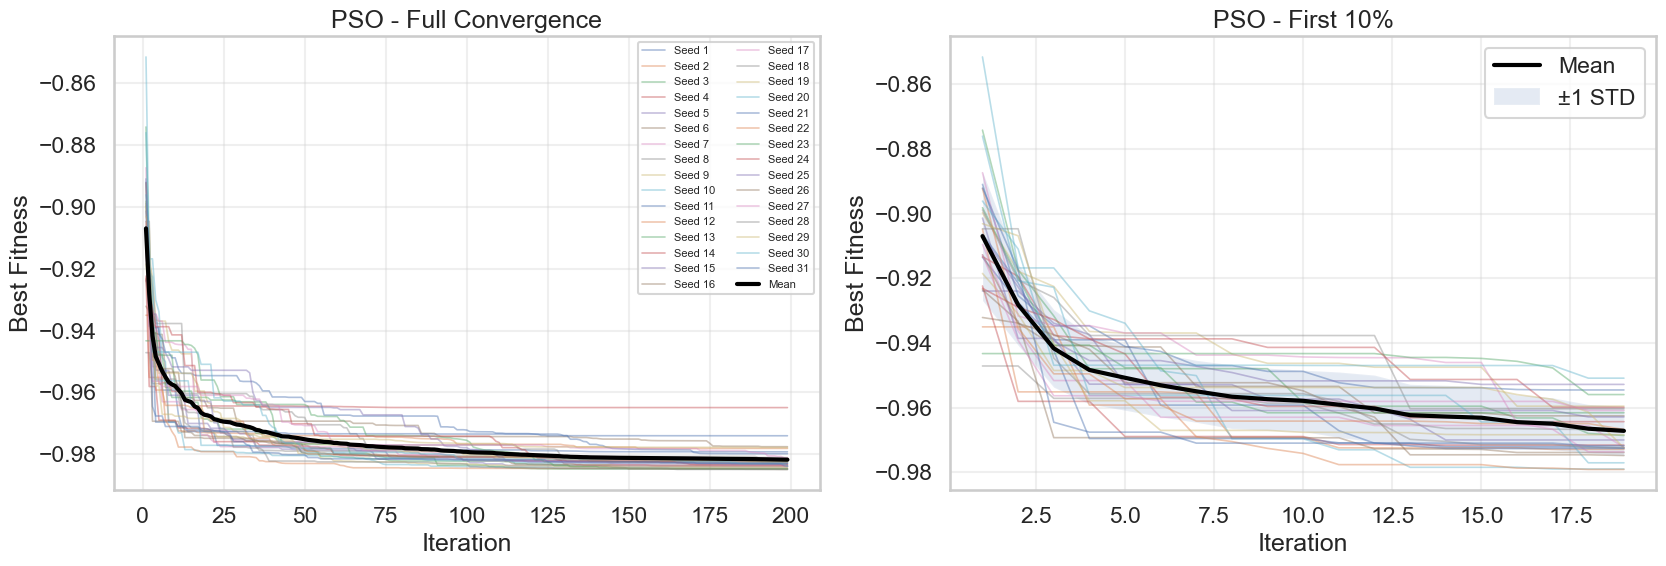

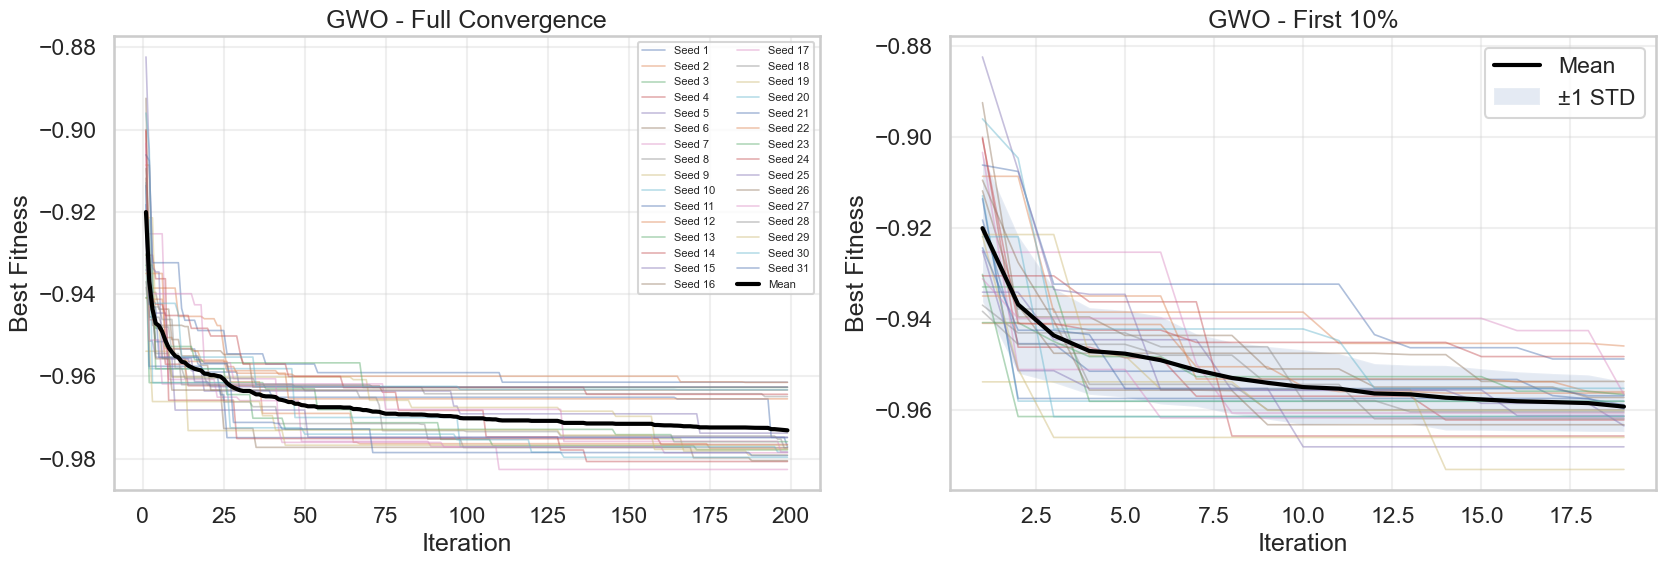

In [105]:
plot_all_results(
    all_results,
    # algorithms=["IGWO", "GWO", "PSO"]
)
plot_individual_convergence(
    all_results,
    # algorithms=["IGWO", "GWO", "PSO"],
    zoom=0.10
)

In [106]:
summary = create_summary_table(all_results)

display(summary.round(5))

summary.to_csv(
    f"results/B_Northern outage_algorithm_comparison.csv",
    index=False
)

best_table = create_best_solutions_table(all_results)
display(best_table.round(3))
best_table.to_csv(f"results/B_Northern outage_best_solutions.csv", index=False)

,Algorithm,Mean Fitness,Std Fitness,Best Fitness,Worst Fitness,Mean Runtime (s),Std Runtime (s)
0,GA,-0.98443,0.00113,-0.98557,-0.97907,13.92313,2.44926
1,PSO,-0.98173,0.00407,-0.98489,-0.96490,5.15929,0.75798
2,GWO,-0.97313,0.00720,-0.98264,-0.96142,6.00642,0.15572


,Algorithm,Best Fitness,x1,y1,p1,h1,c1,z1,x2,y2,...,p3,h3,c3,z3,x4,y4,p4,h4,c4,z4
0,GA,-0.986,2.716,3.661,1.997,4,1,1,8.587,2.523,...,1.990,4,1,1,6.729,7.812,1.992,4,1,1
1,PSO,-0.985,0.814,2.994,1.237,4,1,1,7.910,2.484,...,1.998,4,1,1,2.216,4.600,1.997,4,1,1
2,GWO,-0.983,8.108,2.579,1.588,4,1,1,3.109,4.102,...,2.000,4,1,1,9.060,5.240,0.276,4,1,1



GA | Best fitness: -0.985566


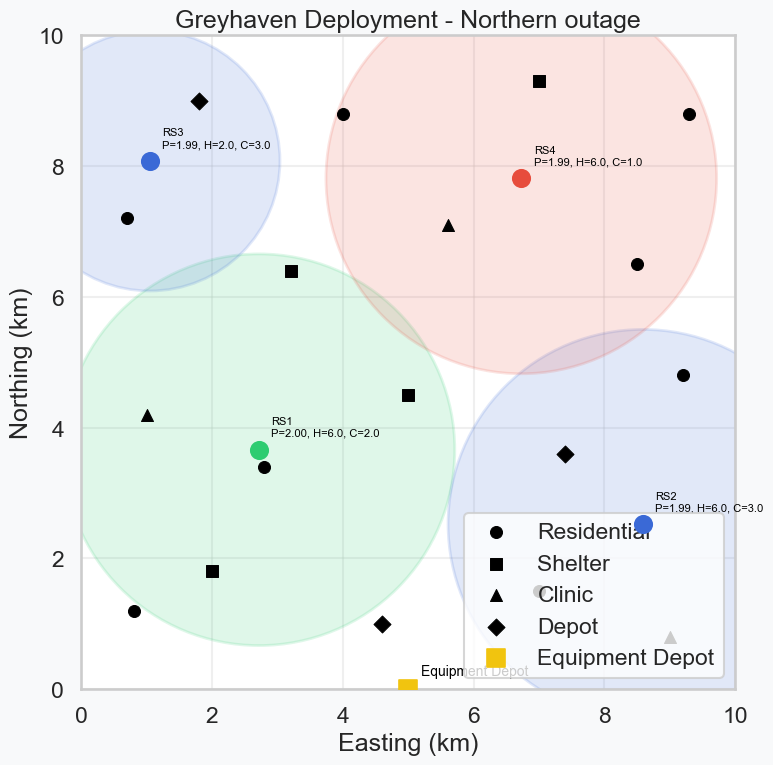


PSO | Best fitness: -0.984889


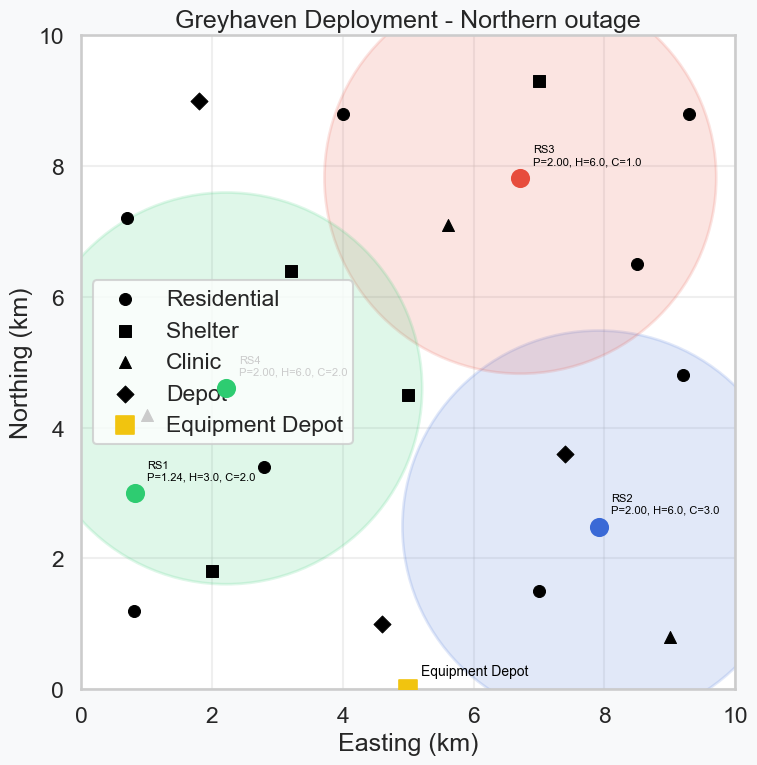


GWO | Best fitness: -0.982640


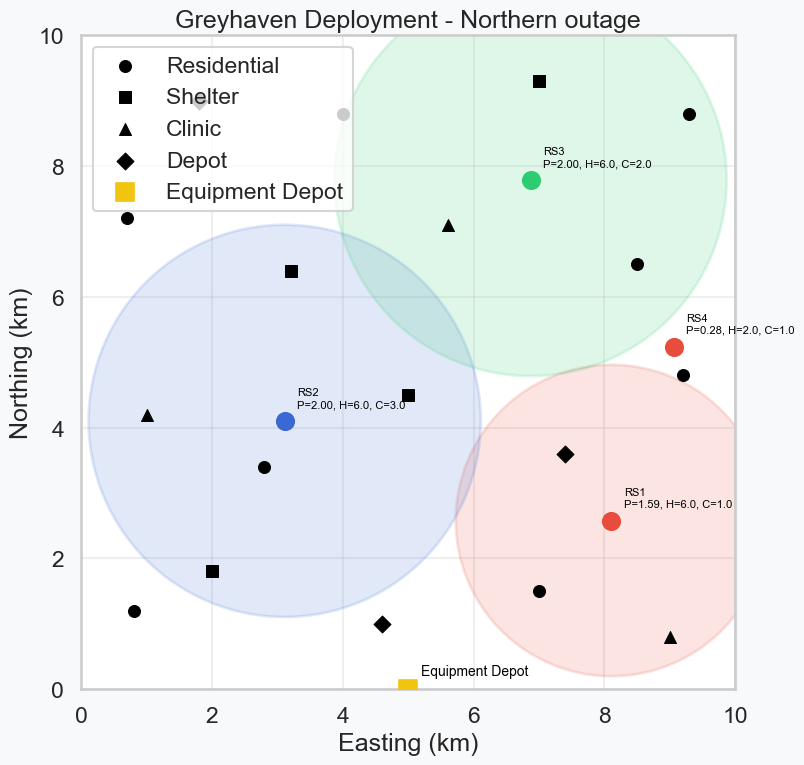

In [107]:
plot_best_deployments(
    all_results,
    situation="Northern outage",
    assignment="B"
)

# Print All Mealpy Optimization Algorithm names

In [3]:
found = {}
for m in pkgutil.walk_packages(mealpy.__path__, "mealpy."):
    if ".utils" in m.name:
        continue
    try:
        mod = importlib.import_module(m.name)
    except Exception:
        continue
    for name, cls in inspect.getmembers(mod, inspect.isclass):
        if issubclass(cls, Optimizer) and cls is not Optimizer and cls.__module__ == mod.__name__:
            found[name] = m.name.split(".")[1]   # category, e.g. swarm_based

print(len(found))
print([n for n in found])

234
['DevBBO', 'OriginalBBO', 'OriginalBBOA', 'OriginalBCO', 'OriginalBMO', 'OriginalEOA', 'OriginalIWO', 'DevSBO', 'OriginalSBO', 'DevSMA', 'OriginalSMA', 'DevSOA', 'OriginalSOA', 'OriginalSOS', 'DevTPO', 'OriginalTSA', 'DevVCS', 'OriginalVCS', 'OriginalWHO', 'OCRO', 'OriginalCRO', 'JADE', 'OriginalDE', 'SADE', 'SAP_DE', 'LevyEP', 'OriginalEP', 'CMA_ES', 'LevyES', 'OriginalES', 'Simple_CMA_ES', 'OriginalFPA', 'BaseGA', 'EliteMultiGA', 'EliteSingleGA', 'MultiGA', 'OriginalGA', 'SingleGA', 'OriginalMA', 'L_SHADE', 'OriginalSHADE', 'OriginalAFT', 'DevBRO', 'OriginalBRO', 'ImprovedBSO', 'OriginalBSO', 'OriginalCA', 'OriginalCDDO', 'DevCHIO', 'OriginalCHIO', 'DevFBIO', 'OriginalFBIO', 'DevGSKA', 'OriginalGSKA', 'OriginalHBO', 'OriginalHCO', 'OriginalICA', 'DevLCO', 'ImprovedLCO', 'OriginalLCO', 'DevQSA', 'ImprovedQSA', 'LevyQSA', 'OppoQSA', 'OriginalQSA', 'DevSARO', 'OriginalSARO', 'DevSPBO', 'OriginalSPBO', 'OriginalSSDO', 'DevTLO', 'ImprovedTLO', 'OriginalTLO', 'OriginalTOA', 'OriginalWa